# Norm Information, Coherence, and Reliability in Quantum Brain MRI Classification
## Colab study — execution repair, version 2.0.1

**Start in a fresh Colab runtime.** Upload this notebook, choose your settings in
Cell 1, then select **Runtime → Run all**. Run cells in order. CPU is sufficient for
the four/five-qubit models; a GPU accelerates the optional ResNet18 comparator.

| PROFILE | Data and purpose |
|---|---|
| `smoke` | Small synthetic datasets; checks every main cell. Never paper evidence. |
| `pilot` | Real MRI cohorts, one seed and a shorter training/search budget. |
| `paper` | Real MRI cohorts and the original full study budget; the default. |

**Recommended first run:** select `pilot` to check your real-data setup. Select
`paper` for the full experiment. A paper run performs many separate model fits
and may require several Colab sessions. Completed candidates are checkpointed.
Approve the Drive prompt when it appears; if mounting fails, outputs go to local
runtime storage and the notebook prints that location. Download the evidence ZIP
before the runtime ends when using local storage.

Default cohorts are native Figshare three-tumor MRI and a separate four-class
Kaggle benchmark. Their classes and results are reported separately. They may
share source images; Kaggle is not an independent external validation cohort.
The public downloads need roughly 1 GB plus space for extraction and outputs.
If you already have the datasets, fill `FIGSHARE_ROOT` / `KAGGLE_ROOT`; for your
own labelled image folders use `FOLDER_ROOT` and optional `METADATA_CSV`.

Downloads never fall back to synthetic images. Genuine missing data or invalid
configuration produces an actionable message. The optional CNN may be skipped
after a dependency, pretrained-weight download or memory failure; its status is
saved, and no random or fabricated features replace it. Set
`CNN_FAILURE_POLICY = "raise"` if the CNN must succeed for your run.

Outputs include protocol/data hashes, audit ledgers, group splits, checkpoints,
predictions, calibration, uncertainty comparisons, noise/resource diagnostics,
figures, a manuscript working draft, a reporting checklist and an evidence ZIP.
Execution does not guarantee publication, clinical utility or quantum advantage.


## Execution fixes in this revision

- Missing patient IDs no longer crash the Kaggle/folder partition check. Known
  patients remain grouped; missing IDs still prevent a patient-level claim.
- PennyLane, its Lightning plugin and Autoray use a compatible pinned set.
  Existing compatible NumPy/SciPy/Pandas and Torch/Torchvision are preserved.
- Drive mounting, public downloads and optional CNN failures have clear recovery
  paths. Existing local datasets and verified caches can be reused.
- Smaller training subsets and folds use feasible PCA rank, padded to the same
  16-dimensional quantum input. PCA is still fitted only on training images.
- Model/cache identity is deterministic across Python sessions. Unreadable
  candidate caches are quarantined and retrained, with a visible message.
- Dataset-path/metadata validation and native MATLAB patient-ID decoding are
  stricter. Source-holdout checks require all classes in both sides.

**Author validation is recorded in notebook metadata.** Only executed checks
are marked passed. Full publication-budget training is a separate experiment.


## Context & Methods

**Candidate contribution, not a verified first-in-literature claim:** determine whether
coherent norm fusion offers reproducible predictive or reliability benefits after patient
separation, intensity controls, norm-matched classical comparisons and acquisition stress.

The four-qubit amplitude circuit has 24 trainable angles. The passive and coherent five-qubit
variants use the same 24 angles; their fifth-qubit gates are fixed. An additional probability
temperature is learned separately for every model and counted separately.

For normalized direction d and training-scaled norm angle a, define the real lifted state
\(\phi=d\otimes[\cos(a/2),\sin(a/2)]\).
Every circuit here has the form \(\ell_k=\phi^\top\operatorname{Re}(U^\dagger Z_kU)\phi\).
This exact low-dimensional classical realization is tested numerically. It is an inference
equivalent of trained weights, not an independently trained competitor.

For the passive circuit, U is block diagonal in the ancilla basis, giving
\(\ell_k(d,a)=\cos^2(a/2)\ell_k(d,0)+\sin^2(a/2)\ell_k(d,\pi)\).
The coherent circuit inserts fixed H gates between control interactions, allowing cross terms.
Neither construction establishes computational quantum advantage at four/five qubits.

**Prespecified primary endpoint:** patient/unit macro-F1 on one locked test partition.
**Prespecified contrasts:** coherent versus passive, coherent versus amplitude, coherent
versus a validation-selected classical strategy. Two-sided paired unit permutation tests are
Holm corrected as one family. Bootstrap CIs describe held-out-unit sampling conditional on
the trained models; seed variability is reported separately.

**Reliability:** temperature scaling on its own units; label-conditional (Mondrian) split
conformal sets on different units, target coverage 90%. Small calibration classes produce
conservative full-class thresholds. Coverage guarantees require within-class exchangeability;
they do not extend automatically to scanner shifts or corrupted images.

### Cell 1 — Choose the experiment

In [1]:
import os, sys, subprocess, copy
from pathlib import Path

PROFILE = os.getenv("QML_PROFILE", "paper").strip().lower()  # @param ["smoke", "pilot", "paper"]
COHORTS = ["figshare3", "kaggle4"]
USE_DRIVE = os.getenv("QML_USE_DRIVE", "1") == "1"  # @param {type:"boolean"}
FIGSHARE_ROOT = os.getenv("QML_FIGSHARE_ROOT", "")  # folder containing native cjdata .mat files
KAGGLE_ROOT = os.getenv("QML_KAGGLE_ROOT", "")  # already downloaded class-folder dataset
FOLDER_ROOT = os.getenv("QML_FOLDER_ROOT", "")  # use your own class-folder cohort instead
METADATA_CSV = os.getenv("QML_METADATA_CSV", "")  # relative_path, patient_id, source_dataset
EXTERNAL_ROOT = os.getenv("QML_EXTERNAL_ROOT", "")
EXTERNAL_METADATA_CSV = os.getenv("QML_EXTERNAL_METADATA_CSV", "")
EXTERNAL_PROVENANCE_JSON = os.getenv("QML_EXTERNAL_PROVENANCE_JSON", "")
_default_base = Path("/content") if Path("/content").is_dir() else Path.cwd()
RESULTS_ROOT = os.getenv("QML_RESULTS_DIR", str(_default_base / "qml_norm_coherence_v2"))
DATA_CACHE = os.getenv("QML_DATA_CACHE", str(_default_base / "qml_data_cache"))
ENABLE_CNN_PROBE = os.getenv("QML_ENABLE_CNN_PROBE", "1") == "1"
CNN_FAILURE_POLICY = "skip"  # @param ["skip", "raise"]
CNN_BATCH_SIZE = 32
ENABLE_RAW_INTENSITY_ABLATION = True
DOWNLOAD_ZIP = False

PROFILES = {
    "smoke": dict(seeds=[13], epochs=2, patience=2, batch_size=32, lr_grid=[0.03],
                  c_grid=[1.0], bootstrap=80, permutations=80, noise_units=2, shot_reps=2,
                  noise_probs=[0.0, 0.01], shots=[None, 64], fit_slices_per_unit=2),
    "pilot": dict(seeds=[13], epochs=12, patience=4, batch_size=64, lr_grid=[0.03],
                  c_grid=[0.3, 3.0], bootstrap=500, permutations=500, noise_units=4, shot_reps=3,
                  noise_probs=[0.0, 0.005], shots=[None, 256, 1024], fit_slices_per_unit=4),
    "paper": dict(seeds=[13, 29, 47], epochs=40, patience=8, batch_size=128,
                  lr_grid=[0.01, 0.05], c_grid=[0.03, 0.3, 3.0, 30.0],
                  bootstrap=3000, permutations=3000, noise_units=8, shot_reps=5,
                  noise_probs=[0.0, 0.001, 0.005, 0.01], shots=[None, 128, 1024, 4096],
                  fit_slices_per_unit=8),
}
if PROFILE not in PROFILES:
    raise ValueError(f"PROFILE must be one of {list(PROFILES)}; received {PROFILE!r}.")
if CNN_FAILURE_POLICY not in {"skip", "raise"} or CNN_BATCH_SIZE < 1:
    raise ValueError("Use CNN_FAILURE_POLICY='skip' or 'raise', and CNN_BATCH_SIZE >= 1.")
CFG = copy.deepcopy(PROFILES[PROFILE])
SPLIT_SEED = 20261001
SPLIT_FRACTIONS = dict(fit=0.50, selection=0.10, temperature=0.10, conformal=0.10, test=0.20)
ALPHA, PCA_DIM, N_LAYERS = 0.10, 16, 2
PHASH_RADIUS, NEAR_SSIM_THRESHOLD = 3, 0.985
VERSION = "2.0.1"
if PROFILE == "smoke":
    COHORTS, USE_DRIVE, ENABLE_CNN_PROBE = ["synthetic3", "synthetic4"], False, False
elif FOLDER_ROOT:
    COHORTS = ["folder"]
if PROFILE != "smoke" and os.getenv("QML_COHORTS"):
    COHORTS = [name.strip() for name in os.environ["QML_COHORTS"].split(",") if name.strip()]
if not COHORTS or not set(COHORTS) <= {"figshare3", "kaggle4", "folder", "synthetic3", "synthetic4"}:
    raise ValueError("Unknown/empty cohort list: " + repr(COHORTS))
if PROFILE != "smoke" and any(name.startswith("synthetic") for name in COHORTS):
    raise ValueError("Synthetic cohorts are allowed only with PROFILE='smoke'.")
if not 0 < ALPHA < 1 or PCA_DIM != 16 or N_LAYERS != 2:
    raise ValueError("This study uses ALPHA in (0,1), 16 input amplitudes and two circuit layers.")
if not all(v > 0 for v in SPLIT_FRACTIONS.values()) or abs(sum(SPLIT_FRACTIONS.values()) - 1) > 1e-12:
    raise ValueError("SPLIT_FRACTIONS must be positive and sum to one.")
print("Profile:", PROFILE, "| Cohorts:", COHORTS)
print("Smoke/pilot results are engineering evidence only. Run cells from top to bottom.")


Profile: paper | Cohorts: ['figshare3', 'kaggle4']
Smoke/pilot results are engineering evidence only. Run cells from top to bottom.


### Cell 2 — Install pinned study dependencies

In [2]:
import importlib.metadata
from packaging.requirements import Requirement

# Pin the quantum ecosystem together; do not upgrade/downgrade a compatible
# Colab numerical stack or its preinstalled Torch/Torchvision pair.
requirements = [
    "pennylane==0.42.3", "pennylane-lightning==0.42.0", "autoray==0.7.2",
    "numpy>=1.26,<2.4", "scipy>=1.11,<2", "pandas>=2.0,<3",
    "scikit-learn>=1.6.1,<2", "ImageHash==4.3.2", "h5py>=3.14,<4",
    "kagglehub==0.3.13", "scikit-image>=0.25.2,<0.27",
    "matplotlib>=3.7,<4", "nbformat>=5.10.4,<6", "tabulate>=0.9,<1",
    "requests>=2.31,<3", "tqdm>=4.66,<5",
]
missing = []
for requirement in requirements:
    req = Requirement(requirement)
    try:
        version = importlib.metadata.version(req.name)
        if version not in req.specifier:
            missing.append(requirement)
    except importlib.metadata.PackageNotFoundError:
        missing.append(requirement)
if missing and os.getenv("QML_SKIP_INSTALL", "0") != "1":
    print("Installing:", ", ".join(missing), flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--no-warn-script-location",
         "--upgrade-strategy", "only-if-needed", *requirements],
        text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    )
    if result.returncode:
        print("\n".join(result.stdout.splitlines()[-30:]))
        raise RuntimeError("Dependency installation failed. Check internet access, then rerun Cell 2 in a fresh runtime.")
elif missing:
    raise RuntimeError("QML_SKIP_INSTALL=1 but these requirements are missing/incompatible: " + ", ".join(missing))

# A separate interpreter detects binary/import incompatibilities before data downloads.
check = subprocess.run([sys.executable, "-c",
    "import numpy, scipy, pandas, sklearn, h5py, skimage, imagehash, pennylane; "
    "pennylane.device('default.qubit', wires=2); print('Core imports OK')"],
    text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
if check.returncode:
    print(check.stdout[-5000:])
    raise RuntimeError("Core dependency check failed. Start a fresh runtime and run Cells 1–3 again.")
for module_name in ["numpy", "scipy", "pandas", "sklearn", "h5py", "skimage", "pennylane", "autoray"]:
    module = sys.modules.get(module_name)
    distribution = {"sklearn": "scikit-learn", "skimage": "scikit-image"}.get(module_name, module_name)
    if module is not None and hasattr(module, "__version__"):
        if str(module.__version__) != importlib.metadata.version(distribution):
            raise RuntimeError(f"{module_name} was already imported before its version changed. Restart the runtime, then Run all.")
print("Setup complete. Compatible core imports verified. Torch/torchvision are checked only for the optional CNN.")


Installing: pennylane==0.42.3, pennylane-lightning==0.42.0, autoray==0.7.2, kagglehub==0.3.13
Setup complete. Compatible core imports verified. Torch/torchvision are checked only for the optional CNN.


### Cell 3 — Imports, output location and environment record

In [3]:
import contextlib, hashlib, importlib.metadata, json, math, platform, random, shutil, time
import urllib.request, urllib.error, zipfile, warnings, pickle, zlib
from collections import Counter, defaultdict
from pathlib import Path
import h5py, imagehash, joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import scipy, sklearn
from PIL import Image, ImageDraw
from IPython.display import Markdown, display
from scipy.optimize import minimize, minimize_scalar
from scipy.special import softmax, logsumexp
from scipy.stats import chi2_contingency
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, roc_auc_score, log_loss)
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from skimage.metrics import structural_similarity

try:
    import google.colab
    IN_COLAB=True
except ImportError:
    IN_COLAB=False
DRIVE_STATUS = "disabled" if not USE_DRIVE else "not_in_colab"
if USE_DRIVE and IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        if not Path("/content/drive/MyDrive").is_dir():
            raise OSError("MyDrive is not available after mounting.")
        DRIVE_STATUS = "mounted"
        if "QML_RESULTS_DIR" not in os.environ:
            RESULTS_ROOT = "/content/drive/MyDrive/QML_Norm_Coherence_v2"
    except (Exception, SystemExit) as exc:
        DRIVE_STATUS = "mount_failed_local_storage"
        print(f"Drive mount unavailable ({exc}). Using local outputs: {RESULTS_ROOT}")
        print("Download the evidence ZIP before this runtime ends.")
ROOT, CACHE = Path(RESULTS_ROOT), Path(DATA_CACHE)
ROOT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, default=str))
    temporary.replace(path)
def atomic_joblib(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    joblib.dump(value, temporary)
    temporary.replace(path)
def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()
def file_sha(path, method="sha256"):
    h = hashlib.new(method)
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()
ENV = {name: importlib.metadata.version(name) for name in [
    "numpy", "scipy", "pandas", "scikit-learn", "pennylane", "h5py", "scikit-image", "ImageHash"]}
ENV.update(python=sys.version, platform=platform.platform())
STORAGE_STATUS = dict(drive=DRIVE_STATUS, results=str(ROOT), cache=str(CACHE))
write_json(ROOT / "storage_status.json", STORAGE_STATUS)
print("Results:", ROOT, "| Cache:", CACHE)
write_json(ROOT / "environment.json", ENV)
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(ROOT / "environment_freeze.txt").write_text(freeze)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 240, "font.size": 10})
display(pd.Series(ENV).to_frame("value"))
def load_candidate_cache(path, identity):
    if not Path(path).exists():
        return None
    try:
        record = joblib.load(path)
        if not isinstance(record, dict) or record.get("identity") != identity:
            raise ValueError("Cache identity/format does not match this candidate.")
        if not {"name", "score", "fit_seconds", "trainable"}.issubset(record):
            raise ValueError("Candidate checkpoint is incomplete.")
        if not np.isfinite(np.asarray(record["score"], float)).all():
            raise ValueError("Candidate score is not finite.")
        return record
    except (EOFError, OSError, ValueError, KeyError, TypeError, ImportError, IndexError, AttributeError,
            pickle.UnpicklingError, zlib.error) as exc:
        quarantined = Path(str(path) + ".invalid")
        Path(path).replace(quarantined)
        print(f"Retraining unusable checkpoint {Path(path).name}: {exc}", flush=True)
        return None


/usr/local/lib/python3.12/dist-packages/pennylane/__init__.py:196: RuntimeWarning: PennyLane is not yet compatible with JAX versions > 0.6.2. You have version 0.7.2 installed. Please downgrade JAX to 0.6.2 to avoid runtime errors using python -m pip install jax~=0.6.0 jaxlib~=0.6.0
  warnings.warn(


Drive mount unavailable (Mounting drive is unsupported in this environment. Use PyDrive2 instead. See examples at https://colab.research.google.com/notebooks/io.ipynb#scrollTo=7taylj9wpsA2.). Using local outputs: /content/qml_norm_coherence_v2
Download the evidence ZIP before this runtime ends.
Results: /content/qml_norm_coherence_v2 | Cache: /content/qml_data_cache


,value
numpy,2.0.2
scipy,1.16.3
pandas,2.3.3
scikit-learn,1.6.1
pennylane,0.42.3
h5py,3.16.0
scikit-image,0.25.2
ImageHash,4.3.2
python,"3.12.13 (main, Mar 4 2026, 09:23:07) [GCC 11...."
platform,Linux-6.18.48+-x86_64-with-glibc2.35


### Cell 4 — Freeze the protocol and protect test-set reuse
Changing the data, split, preprocessing, model family, grid or software creates a new run.
Do not alter the study after looking at test outcomes. A new hash cannot make reuse of the same
test patients scientifically independent; retain a prospective new cohort for confirmation.

In [4]:
PROTOCOL = dict(version=VERSION, profile=PROFILE, cfg=CFG, cohorts=COHORTS,
    pca_dim=PCA_DIM, layers=N_LAYERS, split_seed=SPLIT_SEED,
    split_fractions=SPLIT_FRACTIONS, phash_radius=PHASH_RADIUS, ssim=NEAR_SSIM_THRESHOLD,
    alpha=ALPHA, intensity_modes=["robust", "raw"] if ENABLE_RAW_INTENSITY_ABLATION else ["robust"],
    cnn_probe=ENABLE_CNN_PROBE, endpoint="unit_macro_f1",
    primary_contrasts=["Coherent5-Passive5", "Coherent5-Amplitude4", "Coherent5-SelectedClassical"],
    unit_aggregation="mean calibrated slice probabilities; one diagnosis per analysis unit",
    environment=ENV,
    clinical_scope="retrospective slice classification; no clinical deployment claim",
    external_root=EXTERNAL_ROOT, external_metadata=EXTERNAL_METADATA_CSV,
    external_provenance=EXTERNAL_PROVENANCE_JSON,
    folder_root=FOLDER_ROOT, metadata_csv=METADATA_CSV,
    figshare_root=FIGSHARE_ROOT, kaggle_root=KAGGLE_ROOT,
    cnn_failure_policy=CNN_FAILURE_POLICY,
    pca_small_sample_policy="fit feasible rank on training only; zero-pad to 16")
PROTOCOL_HASH = digest(PROTOCOL)
RUN_ROOT = ROOT / f"{PROFILE}_{PROTOCOL_HASH[:12]}"
RUN_ROOT.mkdir(exist_ok=True)
write_json(RUN_ROOT / "protocol.json", PROTOCOL)
write_json(RUN_ROOT / "storage_status.json", STORAGE_STATUS)
print("Protocol hash:", PROTOCOL_HASH)
print("Run directory:", RUN_ROOT)

Protocol hash: bd11a4851076712d77f51af5a70c8bf8449c50c9be145d66f482ae64053391d6
Run directory: /content/qml_norm_coherence_v2/paper_bd11a4851076


## Data
### Cell 5 — Download helpers with provenance and archive checks
The Figshare release is fixed to version 8 and the downloaded file MD5 is verified against the
publisher API. Kaggle's release/path and all input content hashes are recorded. A download
failure raises a specific error; synthetic data never replace a failed real-data download.

In [5]:
def get_json(url, attempts=3):
    for attempt in range(attempts):
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "QML-MRI-Study/2.0.1"})
            with urllib.request.urlopen(request, timeout=60) as response:
                return json.load(response)
        except (OSError, ValueError) as exc:
            if attempt + 1 == attempts:
                raise RuntimeError(f"Could not read {url}. Check internet access or supply a local dataset root.") from exc
            print(f"Metadata retry {attempt + 1}/{attempts}: {type(exc).__name__}", flush=True)
            time.sleep(2 ** attempt)

def download_url(url, destination, expected_md5=None, attempts=4):
    import requests
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.is_file() and destination.stat().st_size > 0:
        if not expected_md5 or file_sha(destination, "md5") == expected_md5:
            return destination
    temp = destination.with_suffix(destination.suffix + ".part")
    session = requests.Session()
    for attempt in range(attempts):
        try:
            # Figshare redirects to S3 URLs with short expiry. A fresh query and
            # a reused connection avoid cached/expired redirects on retries.
            request_url = url
            if (urllib.parse.urlsplit(url).hostname or "").endswith("figshare.com"):
                request_url += ("&" if "?" in url else "?") + "qml_cachebust=" + str(time.time_ns())
            print("Downloading", destination.name, flush=True)
            with session.get(request_url, stream=True, timeout=(20, 90),
                    headers={"User-Agent": "QML-MRI-Study/2.0.1", "Cache-Control": "no-cache"}) as response, open(temp, "wb") as handle:
                response.raise_for_status()
                expected_length = response.headers.get("Content-Length")
                if response.headers.get("Content-Encoding"):
                    expected_length = None
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        handle.write(chunk)
            if temp.stat().st_size == 0 or (expected_length and temp.stat().st_size != int(expected_length)):
                raise OSError("Download is empty or truncated.")
            if expected_md5 and file_sha(temp, "md5") != expected_md5:
                raise ValueError("Publisher MD5 mismatch: " + destination.name)
            temp.replace(destination)
            return destination
        except (requests.RequestException, OSError, ValueError) as exc:
            temp.unlink(missing_ok=True)
            if attempt + 1 == attempts:
                raise RuntimeError(f"Download failed for {destination.name}. Retry Cell 10 or set the local cohort root in Cell 1.") from exc
            status = getattr(getattr(exc, "response", None), "status_code", None)
            print(f"Download retry {attempt + 1}/{attempts}: {type(exc).__name__}"
                  + (f" (HTTP {status}; requesting a fresh publisher link)" if status else ""), flush=True)
            time.sleep(2 ** attempt)

def extract_checked(archive, folder):
    folder = Path(folder).resolve()
    folder.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as handle:
        for info in handle.infolist():
            target = (folder / info.filename).resolve()
            if folder not in target.parents and target != folder:
                raise ValueError("Unsafe archive member: " + info.filename)
        handle.extractall(folder)

def native_mat_paths(folder):
    return [p for p in sorted(Path(folder).rglob("*"))
            if p.is_file() and p.suffix.lower() == ".mat" and p.stem.lower() not in {"cvind", "readme"}]

def fetch_figshare():
    if FIGSHARE_ROOT:
        folder = Path(FIGSHARE_ROOT).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError(f"FIGSHARE_ROOT does not exist: {folder}. Mount Drive first or correct Cell 1.")
        paths = native_mat_paths(folder)
        if not paths:
            raise FileNotFoundError("No native cjdata .mat files found under FIGSHARE_ROOT: " + str(folder))
        return folder, paths, dict(license="verify supplied local dataset license", local_files=True)
    folder = CACHE / "figshare_1512427_v8"
    folder.mkdir(parents=True, exist_ok=True)
    metadata_path = folder / "publisher_metadata.json"
    try:
        article = get_json("https://api.figshare.com/v2/articles/1512427/versions/8")
        write_json(metadata_path, article)
    except RuntimeError:
        if not metadata_path.is_file():
            raise
        article = json.loads(metadata_path.read_text())
        print("Publisher API unavailable; using previously saved version-8 metadata and verifying cached MD5s.")
    for entry in article["files"]:
        name = Path(entry["name"]).name
        # Publisher metadata already records provenance. Auxiliary PDF/TXT
        # downloads must not block the required MRI archives.
        if name.lower().endswith(".zip"):
            local = download_url(entry["download_url"], folder / name, entry.get("supplied_md5") or entry.get("computed_md5"))
            if name.lower().endswith(".zip"):
                marker = folder / (name + ".extracted")
                archive_hash = file_sha(local)
                needs_extract = not marker.is_file() or marker.read_text().strip() != archive_hash
                if not needs_extract:
                    with zipfile.ZipFile(local) as handle:
                        needs_extract = any(not (folder / entry.filename).exists() for entry in handle.infolist()
                                            if entry.filename.lower().endswith(".mat"))
                if needs_extract:
                    print("Extracting", name, flush=True)
                    extract_checked(local, folder)
                    marker.write_text(archive_hash)
    paths = native_mat_paths(folder)
    if not paths:
        raise FileNotFoundError("No cjdata MAT files found. Set FIGSHARE_ROOT to the extracted native dataset.")
    return folder, paths, article


### Cell 6 — Read native patient IDs and tumor masks; do not infer subjects from filenames

In [6]:
def decode_patient_id(value):
    if isinstance(value, bytes):
        return value.decode("utf-8").strip()
    if isinstance(value, str):
        return value.strip()
    array = np.asarray(value).ravel()
    if array.dtype.kind in {"U", "S"}:
        return "".join(v.decode("utf-8") if isinstance(v, bytes) else str(v) for v in array).strip()
    if array.dtype.kind in {"i", "u", "f"} and len(array) > 1:
        codes = [int(v) for v in array if int(v)]
        if all(0 < v <= 0x10FFFF for v in codes):
            return "".join(chr(v) for v in codes).strip()
    return "".join(str(v) for v in array).strip()

def read_cheng_mat(path):
    # Original files use MATLAB v7.3/HDF5. Older scipy MAT files are also accepted.
    if h5py.is_hdf5(path):
        with h5py.File(path, "r") as f:
            g = f["cjdata"]
            label = int(np.asarray(g["label"]).squeeze())
            pid = decode_patient_id(np.asarray(g["PID"]))
            image = np.asarray(g["image"]).T
            mask = np.asarray(g["tumorMask"]).T.astype(bool) if "tumorMask" in g else None
    else:
        g = scipy.io.loadmat(path, simplify_cells=True)["cjdata"]
        label = int(np.asarray(g["label"]).squeeze())
        raw_pid = g["PID"]
        pid = decode_patient_id(raw_pid)
        image = np.asarray(g["image"])
        mask = np.asarray(g["tumorMask"]).astype(bool) if "tumorMask" in g else None
    if label not in {1, 2, 3} or not pid.strip() or image.ndim != 2:
        raise ValueError("Invalid cjdata label/PID/image: " + str(path))
    if mask is not None and mask.shape != image.shape:
        raise ValueError("Mask and image orientation mismatch: " + str(path))
    return image, mask, pid.strip(), {1: "meningioma", 2: "glioma", 3: "pituitary"}[label]

ALIASES = {"glioma": "glioma", "gliomatumor": "glioma",
    "meningioma": "meningioma", "meningiomatumor": "meningioma",
    "pituitary": "pituitary", "pituitarytumor": "pituitary",
    "notumor": "no_tumor", "notumour": "no_tumor", "normal": "no_tumor"}
def folder_label(path):
    for part in reversed(Path(path).parts[:-1]):
        token = "".join(c for c in part.lower() if c.isalnum())
        if token in ALIASES:
            return ALIASES[token]
    return None
def scan_folder(root, metadata_csv=""):
    root = Path(root).expanduser().resolve()
    if not root.is_dir():
        raise FileNotFoundError(f"Dataset folder does not exist: {root}. Mount Drive or correct the root in Cell 1.")
    rows = []
    for p in sorted(root.rglob("*")):
        if p.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
            continue
        label = folder_label(p)
        if label:
            rows.append(dict(path=str(p.resolve()), relative_path=p.relative_to(root).as_posix(),
                label=label, patient_id="", source_dataset="unknown", reader="image", mask_path=""))
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise ValueError("No class-labelled images found at " + str(root))
    if metadata_csv:
        metadata_path = Path(metadata_csv).expanduser()
        if not metadata_path.is_file():
            raise FileNotFoundError("Metadata CSV not found: " + str(metadata_path))
        meta = pd.read_csv(metadata_path, dtype=str, keep_default_na=False).fillna("")
        required = ["relative_path", "patient_id", "source_dataset"]
        if not set(required).issubset(meta.columns):
            raise ValueError("Metadata requires " + ", ".join(required))
        meta["relative_path"] = meta.relative_path.str.replace("\\", "/", regex=False).str.strip().str.replace(r"^\./", "", regex=True)
        for column in ["patient_id", "source_dataset"]:
            meta[column] = meta[column].str.strip()
        if meta.relative_path.duplicated().any():
            raise ValueError("Duplicate metadata keys.")
        unmatched = set(meta.relative_path) - set(frame.relative_path)
        if unmatched:
            raise ValueError(f"{len(unmatched)} metadata paths do not match images.")
        frame = frame.drop(columns=["patient_id", "source_dataset"]).merge(meta[required],
            on="relative_path", how="left", validate="one_to_one").fillna("")
        frame.loc[frame.source_dataset.eq(""), "source_dataset"] = "unknown"
    return frame
def read_image_row(row):
    if row["reader"] == "cheng":
        return read_cheng_mat(row["path"])[0]
    with Image.open(row["path"]) as im:
        return np.asarray(im.convert("L"))
def normalize_image(array, mode="robust"):
    x = np.asarray(array, dtype=np.float32)
    if not np.isfinite(x).all() or x.ndim != 2:
        raise ValueError("Image is not a finite 2D array")
    if mode == "robust":
        lo, hi = np.percentile(x, [1, 99])
        x = np.clip((x - lo) / max(hi - lo, 1e-6), 0, 1)
    elif mode == "raw":
        # Preserve relative native signal magnitude. This is an acquisition-shortcut diagnostic.
        denominator = 255.0 if np.asarray(array).dtype == np.uint8 else 65535.0
        x = np.clip(x / denominator, 0, 1)
    else:
        raise KeyError(mode)
    return x
def resize_float(x, side=32):
    return np.asarray(Image.fromarray(np.asarray(x, np.float32)).resize(
        (side, side), Image.Resampling.BILINEAR), dtype=np.float32)

### Cell 7 — Synthetic dataset for execution checks only

In [7]:
def make_synthetic():
    folder = CACHE / "synthetic4"
    folder.mkdir(exist_ok=True)
    rng, rows = np.random.default_rng(112), []
    for k, name in enumerate(["glioma", "meningioma", "no_tumor", "pituitary"]):
        (folder / name).mkdir(exist_ok=True)
        for patient in range(20):
            for sl in range(2):
                x = rng.normal(0.15, 0.035, (64, 64))
                yy, xx = np.mgrid[:64, :64]
                brain = ((xx-32)/22)**2 + ((yy-32)/28)**2 < 1
                x[brain] += 0.20
                if name != "no_tumor":
                    center = [(23, 28), (18, 23), (0, 0), (32, 44)][k]
                    x[(xx-center[0])**2+(yy-center[1])**2 < (5+k)**2] += 0.4
                x += patient * 0.0007
                p = folder / name / f"p{patient:03d}_s{sl}.png"
                Image.fromarray((np.clip(x, 0, 1)*255).astype("uint8")).save(p)
                rows.append(dict(path=str(p), relative_path=p.relative_to(folder).as_posix(),
                    label=name, patient_id=f"synthetic_{name}_{patient}",
                    source_dataset="synthetic_A" if patient % 2 else "synthetic_B",
                    reader="image", mask_path=""))
        duplicate = folder / name / "duplicate.png"
        shutil.copy2(folder / name / "p000_s0.png", duplicate)
        original = next(r for r in rows if r["label"] == name)
        rows.append(dict(original, path=str(duplicate), relative_path=duplicate.relative_to(folder).as_posix()))
    return pd.DataFrame(rows), {"synthetic": True, "purpose": "execution check only"}

def acquire_cohort(name):
    if name in {"synthetic3","synthetic4"}:
        frame,provenance=make_synthetic()
        if name=="synthetic3": frame=frame.loc[frame.label.ne("no_tumor")].reset_index(drop=True)
        return frame,dict(provenance,taxonomy=name)
    if name == "figshare3":
        folder, paths, article = fetch_figshare()
        rows = []
        for p in paths:
            if not h5py.is_hdf5(p):
                # cvind files in an unexpected nested folder are skipped, not mislabeled as scans.
                header = scipy.io.whosmat(p)
                if not any(item[0] == "cjdata" for item in header):
                    continue
            image, mask, pid, label = read_cheng_mat(p)
            rows.append(dict(path=str(p.resolve()), relative_path=p.relative_to(folder).as_posix(),
                label=label, patient_id="cheng::" + pid, source_dataset="figshare_cheng",
                reader="cheng", mask_path=str(p.resolve()) if mask is not None else ""))
        return pd.DataFrame(rows), dict(url="https://doi.org/10.6084/m9.figshare.1512427.v8",
            publisher_version=8, license=article.get("license"), metadata_path=str(folder/"publisher_metadata.json"),
            note="Institution/scanner labels are not reconstructed; source name is not a site identifier.")
    if name == "kaggle4":
        if KAGGLE_ROOT:
            root = Path(KAGGLE_ROOT).expanduser().resolve()
        else:
            import kagglehub
            from kagglehub import clients as kaggle_clients
            # Kagglehub 0.3.13 defaults to a 5-second connection deadline,
            # which is too short on some Colab/proxy connections.
            kaggle_clients.DEFAULT_CONNECT_TIMEOUT = 30
            kaggle_clients.DEFAULT_READ_TIMEOUT = 90
            os.environ.setdefault("KAGGLEHUB_CACHE", str(CACHE / "kagglehub"))
            root = None
            last_error = None
            for attempt in range(3):
                try:
                    root = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))
                    break
                except Exception as exc:
                    last_error = exc
                    if attempt < 2:
                        print(f"Kaggle download retry {attempt + 1}/3: {type(exc).__name__}", flush=True)
                        time.sleep(2 ** attempt)
            if root is None:
                raise RuntimeError("Kaggle download failed. Download/extract the public dataset, then set KAGGLE_ROOT in Cell 1.") from last_error
        return scan_folder(root), dict(handle="masoudnickparvar/brain-tumor-mri-dataset",
            resolved_path=str(root), note="Composite benchmark; patient and original-source metadata unavailable by default.")
    if name == "folder":
        return scan_folder(FOLDER_ROOT, METADATA_CSV), dict(root=FOLDER_ROOT, metadata=METADATA_CSV)
    raise KeyError(name)

### Cell 8 — Fingerprints, candidate near-duplicates and conservative exclusions

In [8]:
class DSU:
    def __init__(self, n):
        self.parent = list(range(n))
    def find(self, i):
        while self.parent[i] != i:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return i
    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b:
            self.parent[max(a, b)] = min(a, b)
class BKTree:
    def __init__(self):
        self.root = None
    def add(self, value, index):
        if self.root is None:
            self.root = [value, [index], {}]
            return
        node = self.root
        while True:
            distance = (node[0] ^ value).bit_count()
            if distance == 0:
                node[1].append(index)
                return
            if distance not in node[2]:
                node[2][distance] = [value, [index], {}]
                return
            node = node[2][distance]
    def search(self, value, radius):
        stack, found = ([self.root] if self.root else []), []
        while stack:
            node = stack.pop()
            distance = (node[0] ^ value).bit_count()
            if distance <= radius:
                found.extend(node[1])
            stack.extend(child for d, child in node[2].items()
                         if distance-radius <= d <= distance+radius)
        return found

def audit_manifest(frame, folder):
    frame = frame.copy().reset_index(drop=True)
    required = {"path", "relative_path", "label", "patient_id", "source_dataset", "reader", "mask_path"}
    if frame.empty or not required.issubset(frame.columns):
        raise ValueError("Dataset manifest is empty or missing required columns: " + repr(sorted(required - set(frame.columns))))
    for column in ["patient_id", "source_dataset"]:
        frame[column] = frame[column].fillna("").astype(str).str.strip()
    frame.loc[frame.source_dataset.eq(""), "source_dataset"] = "unknown"
    frame=frame.drop(columns=["file_sha","pixel_sha","phash","width","height","valid",
        "image_id","analysis_unit","label_id","partition"],errors="ignore")
    folder.mkdir(parents=True, exist_ok=True)
    fingerprints, small, excluded = [], [], []
    for i, row in frame.iterrows():
        try:
            x = read_image_row(row)
            gray = (resize_float(normalize_image(x), 64)*255).astype("uint8")
            # Exact means native pixels/shape/dtype, not an equality after 32x32 resizing.
            pix = hashlib.sha256(str((x.shape, str(x.dtype))).encode() + x.tobytes()).hexdigest()
            fingerprints.append(dict(file_sha=file_sha(row.path), pixel_sha=pix,
                phash=str(imagehash.phash(Image.fromarray(gray))),
                width=x.shape[1], height=x.shape[0], valid=True))
            small.append(gray)
        except Exception as exc:
            fingerprints.append(dict(file_sha="", pixel_sha="", phash="", width=0, height=0, valid=False))
            small.append(None)
            excluded.append(dict(relative_path=row.relative_path, reason="unreadable", detail=str(exc)))
    frame = pd.concat([frame, pd.DataFrame(fingerprints)], axis=1)
    frame["image_id"] = [digest([r.relative_path, r.file_sha])[:24] for r in frame.itertuples()]
    valid = frame.valid.to_numpy()
    bad_hashes = set(frame.loc[valid].groupby("pixel_sha").label.nunique().loc[lambda s:s>1].index)
    for row in frame.loc[frame.pixel_sha.isin(bad_hashes)].itertuples():
        excluded.append(dict(relative_path=row.relative_path, reason="exact_pixel_label_conflict",
            detail="quarantined; requires source verification; no automatic relabel"))
    valid &= ~frame.pixel_sha.isin(bad_hashes).to_numpy()
    tree, pairs, dsu = BKTree(), [], DSU(len(frame))
    for i in np.where(valid)[0]:
        value = int(frame.iloc[i].phash, 16)
        for j in tree.search(value, PHASH_RADIUS):
            similarity = float(structural_similarity(small[i], small[j], data_range=255))
            same_patient = bool(frame.iloc[i].patient_id and frame.iloc[i].patient_id == frame.iloc[j].patient_id)
            exact = frame.iloc[i].pixel_sha == frame.iloc[j].pixel_sha
            confirmed = exact or similarity >= NEAR_SSIM_THRESHOLD
            pairs.append(dict(image_a=frame.iloc[i].image_id, image_b=frame.iloc[j].image_id,
                path_a=frame.iloc[i].relative_path, path_b=frame.iloc[j].relative_path,
                hamming=(value ^ int(frame.iloc[j].phash,16)).bit_count(), ssim=similarity,
                same_label=frame.iloc[i].label == frame.iloc[j].label,
                same_patient=same_patient, auto_grouped=confirmed,
                note="similarity-based grouping is conservative; not proof of same patient"))
            if confirmed:
                dsu.union(i, j)
        tree.add(value, i)
    # Merge known subject IDs even with partial coverage, and exact duplicates independently of pHash.
    for column in ["patient_id", "pixel_sha"]:
        subset = frame.loc[valid & frame[column].ne("")]
        for _, ids in subset.groupby(column).groups.items():
            ids = list(ids)
            for j in ids[1:]:
                dsu.union(ids[0], j)
    frame["analysis_unit"] = [f"unit_{dsu.find(i):06d}" for i in range(len(frame))]
    frame = frame.loc[valid].copy()
    linked_patient_counts=frame.groupby("analysis_unit").patient_id.apply(lambda s:len(set(s)-{""}))
    # Duplicate images contribute once, with their connected patient links retained.
    redundant = frame.duplicated("pixel_sha", keep="first")
    for row in frame.loc[redundant].itertuples():
        excluded.append(dict(relative_path=row.relative_path, reason="redundant_exact_pixel_copy", detail="first copy retained"))
    frame = frame.loc[~redundant].copy()
    # Homogeneous units are required for mean-probability patient-level multiclass endpoints.
    ambiguous = set(frame.groupby("analysis_unit").label.nunique().loc[lambda s:s>1].index)
    for row in frame.loc[frame.analysis_unit.isin(ambiguous)].itertuples():
        excluded.append(dict(relative_path=row.relative_path, reason="ambiguous_multi_diagnosis_unit",
            detail="excluded from this single-diagnosis endpoint, not declared a mislabeled patient"))
    frame = frame.loc[~frame.analysis_unit.isin(ambiguous)].reset_index(drop=True)
    labels = sorted(frame.label.unique())
    if not 2 <= len(labels) <= 4:
        raise ValueError("The study requires 2–4 retained classes after auditing; found " + repr(labels))
    frame["label_id"] = frame.label.map({name:i for i,name in enumerate(labels)}).astype(int)
    assert (frame.label_id == frame.label.map({name:i for i,name in enumerate(labels)})).all()
    unit_meta = frame.groupby("analysis_unit").agg(label=("label","first"),
        patients=("patient_id", lambda s: len(set(s)-{""})), slices=("image_id","size")).reset_index()
    unit_meta["patients"]=unit_meta.analysis_unit.map(linked_patient_counts)
    patient_coverage = float(frame.patient_id.ne("").mean())
    linked_patients = int((unit_meta.patients > 1).sum())
    audit = dict(discovered=len(valid), retained=len(frame), excluded=len(excluded),
        patient_coverage=patient_coverage, source_coverage=float(frame.source_dataset.ne("unknown").mean()),
        units=len(unit_meta), linked_multi_patient_units=linked_patients,
        complete_patient_unit_claim=patient_coverage==1.0 and linked_patients==0,
        synthetic=PROFILE=="smoke", exact_conflict_hashes=len(bad_hashes),
        ambiguous_units=len(ambiguous), near_pairs=len(pairs),
        note="Near-duplicate thresholds need manual review and sensitivity analysis for a submission.")
    frame.to_csv(folder/"manifest.csv", index=False)
    pd.DataFrame(excluded, columns=["relative_path","reason","detail"]).to_csv(folder/"exclusions.csv",index=False)
    pd.DataFrame(pairs, columns=["image_a", "image_b", "path_a", "path_b", "hamming", "ssim",
        "same_label", "same_patient", "auto_grouped", "note"]).to_csv(folder/"near_duplicate_review.csv",index=False)
    unit_meta.to_csv(folder/"unit_manifest.csv",index=False)
    write_json(folder/"data_audit.json",audit)
    return frame, labels, audit

### Cell 9 — Locked grouped partition and common training sample budget
The same independent units define all model partitions and seeds. Splitting is randomized
within diagnosis, so label-conditional conformal inference is the confirmatory version.
Paper training retains at most eight predetermined slices per fit unit for compute control;
selection, calibration and test use every retained slice. This cap is part of the estimand,
not a hidden class-balancing or test subsampling step.

In [9]:
PARTITIONS = list(SPLIT_FRACTIONS)
def locked_partitions(frame, k):
    units = frame[["analysis_unit","label_id"]].drop_duplicates().sort_values("analysis_unit")
    rng, assignments = np.random.default_rng(SPLIT_SEED), {}
    for label, sub in units.groupby("label_id"):
        ids = sub.analysis_unit.to_numpy().copy()
        rng.shuffle(ids)
        n = len(ids)
        if n < 10:
            raise ValueError(f"Class {label} has only {n} independent units after auditing. "
                             "This five-way study requires >=10 per class; supply more independent images/subjects. "
                             "Do not lower the threshold or reuse calibration/test units for training.")
        counts = np.floor(n * np.array(list(SPLIT_FRACTIONS.values()))).astype(int)
        counts = np.maximum(counts, 1)
        counts[0] += n-counts.sum()
        start = 0
        for part, count in zip(PARTITIONS, counts):
            for unit in ids[start:start+count]:
                assignments[unit] = part
            start += count
        assert start == n
    result = frame.copy()
    result["partition"] = result.analysis_unit.map(assignments)
    assert result.partition.notna().all()
    assert result.groupby("analysis_unit").partition.nunique().max() == 1
    known_patients = result.loc[result.patient_id.fillna("").ne("")]
    # No known IDs is legitimate for composite image benchmarks, not leakage.
    assert known_patients.empty or known_patients.groupby("patient_id").partition.nunique().max() <= 1
    for part in PARTITIONS:
        assert set(result.loc[result.partition.eq(part),"label_id"]) == set(range(k))
    return result
def fit_indices(frame):
    rng, retained = np.random.default_rng(SPLIT_SEED+1), []
    for _, sub in frame.loc[frame.partition.eq("fit")].groupby("analysis_unit"):
        ids = sub.index.to_numpy()
        retained.extend(rng.choice(ids,size=min(len(ids),CFG["fit_slices_per_unit"]),replace=False))
    return np.array(sorted(retained), dtype=int)
def training_weights(frame, indices, k):
    sub = frame.loc[indices]
    counts = sub.analysis_unit.value_counts()
    w = 1.0 / sub.analysis_unit.map(counts).to_numpy()
    for label in range(k):
        mask = sub.label_id.to_numpy()==label
        w[mask] /= w[mask].sum()
    return w / w.mean()
def aggregate_units(frame, indices, probabilities):
    sub = frame.loc[indices,["analysis_unit","label_id"]].copy()
    for j in range(probabilities.shape[1]):
        sub[f"p{j}"] = probabilities[:,j]
    assert sub.groupby("analysis_unit").label_id.nunique().max()==1
    return sub.groupby("analysis_unit").agg(
        {"label_id":"first", **{f"p{j}":"mean" for j in range(probabilities.shape[1])}}).reset_index()
def unit_probs(table, k):
    return table[[f"p{j}" for j in range(k)]].to_numpy()

### Cell 10 — Acquire, audit and save each cohort independently

In [10]:
DATASETS = {}
for name in COHORTS:
    folder = RUN_ROOT/name
    raw_manifest, provenance = acquire_cohort(name)
    manifest, labels, audit = audit_manifest(raw_manifest,folder)
    manifest = locked_partitions(manifest,len(labels))
    manifest.to_csv(folder/"manifest.csv",index=False)
    write_json(folder/"provenance.json",provenance)
    identity = manifest[["image_id","file_sha","label","patient_id","source_dataset","analysis_unit","partition"]]
    fingerprint = digest(identity.to_dict("records"))
    write_json(folder/"data_fingerprint.json",dict(sha256=fingerprint))
    splits = manifest[["image_id","analysis_unit","patient_id","label","partition"]]
    splits.to_csv(folder/"locked_split_registry.csv",index=False)
    counts = manifest.groupby(["partition","label"]).agg(images=("image_id","size"), units=("analysis_unit","nunique"))
    display(Markdown("**"+name+"** — "+str(len(manifest))+" retained slices"))
    display(counts)
    display(pd.Series(audit).to_frame("value"))
    DATASETS[name] = dict(name=name, folder=folder, manifest=manifest, labels=labels, k=len(labels),
        audit=audit, fingerprint=fingerprint, fit_idx=fit_indices(manifest), provenance=provenance)

Extracting brainTumorDataPublic_1-766.zip
Extracting brainTumorDataPublic_1533-2298.zip
Extracting brainTumorDataPublic_767-1532.zip
Extracting brainTumorDataPublic_2299-3064.zip


**figshare3** — 3064 retained slices

images  units
partition   label                    
conformal   glioma         125      8
            meningioma      69      8
            pituitary      111      6
fit         glioma         787     48
            meningioma     400     42
            pituitary      446     32
selection   glioma         109      8
            meningioma      46      8
            pituitary       76      6
temperature glioma         123      8
            meningioma      74      8
            pituitary      107      6
test        glioma         282     17
            meningioma     119     16
            pituitary      190     12

,value
discovered,3064
retained,3064
excluded,0
patient_coverage,1.0
source_coverage,1.0
units,233
linked_multi_patient_units,0
complete_patient_unit_claim,True
synthetic,False
exact_conflict_hashes,0


**kaggle4** — 6874 retained slices

images  units
partition   label                    
conformal   glioma         177    177
            meningioma     169    167
            no_tumor       144     90
            pituitary      175    175
fit         glioma         892    891
            meningioma     839    838
            no_tumor       850    455
            pituitary      882    880
selection   glioma         177    177
            meningioma     167    167
            no_tumor       173     90
            pituitary      175    175
temperature glioma         177    177
            meningioma     167    167
            no_tumor       191     90
            pituitary      175    175
test        glioma         355    355
            meningioma     339    334
            no_tumor       299    181
            pituitary      351    351

,value
discovered,7200
retained,6874
excluded,326
patient_coverage,0.0
source_coverage,0.0
units,6112
linked_multi_patient_units,0
complete_patient_unit_claim,False
synthetic,False
exact_conflict_hashes,0


### Cell 11 — Inspect class/source balance and shortcut features

In [11]:
def style_vector(row):
    x = resize_float(normalize_image(read_image_row(row),"robust"),64)
    border = np.r_[x[:6].ravel(),x[-6:].ravel(),x[:,:6].ravel(),x[:,-6:].ravel()]
    # No central/tumor intensity feature is called a border-only shortcut.
    return [border.mean(),border.std(),*(np.percentile(border,[10,50,90])),
        row["width"]/max(row["height"],1), math.log1p(row["width"]),math.log1p(row["height"])]
for ds in DATASETS.values():
    frame = ds["manifest"]
    table = pd.crosstab(frame.source_dataset,frame.label)
    table.to_csv(ds["folder"]/"source_by_class.csv")
    display(table)
    known = table.drop(index="unknown",errors="ignore")
    ds["source_confounded"] = bool(len(known)>1 and (known.eq(0).any().any()))
    X_style = np.array([style_vector(row) for _,row in frame.iterrows()])
    ds["X_style"] = X_style
    i_fit, i_val = ds["fit_idx"], frame.index[frame.partition.eq("selection")].to_numpy()
    model = RandomForestClassifier(n_estimators=100,max_depth=4,random_state=SPLIT_SEED,n_jobs=2)
    model.fit(X_style[i_fit],frame.label_id.to_numpy()[i_fit],
        sample_weight=training_weights(frame,i_fit,ds["k"]))
    unit = aggregate_units(frame,i_val,model.predict_proba(X_style[i_val]))
    ds["border_selection_f1"] = f1_score(unit.label_id,unit_probs(unit,ds["k"]).argmax(1),
        labels=np.arange(ds["k"]),average="macro",zero_division=0)
    print(ds["name"],"border/dimensions-only selection macro-F1:",round(ds["border_selection_f1"],3))
    print("This is a shortcut screen, not proof of causal confounding.")

label,glioma,meningioma,pituitary
source_dataset,,,
figshare_cheng,1426,708,930


figshare3 border/dimensions-only selection macro-F1: 0.822
This is a shortcut screen, not proof of causal confounding.


label,glioma,meningioma,no_tumor,pituitary
source_dataset,,,,
unknown,1778,1681,1657,1758


kaggle4 border/dimensions-only selection macro-F1: 0.708
This is a shortcut screen, not proof of causal confounding.


### Cell 12 — Metrics and small-sample coverage intervals

In [12]:
def metrics(y, p):
    k = p.shape[1]
    p = np.clip(np.asarray(p,float),1e-12,1); p /= p.sum(1,keepdims=True)
    y = np.asarray(y,int); pred = p.argmax(1)
    cm = confusion_matrix(y,pred,labels=np.arange(k))
    tp, fn, fp = np.diag(cm), cm.sum(1)-np.diag(cm), cm.sum(0)-np.diag(cm)
    tn = cm.sum()-tp-fn-fp
    confidence, correct = p.max(1), (pred==y).astype(float)
    ece = 0.0
    for lo,hi in zip(np.linspace(0,1,11)[:-1],np.linspace(0,1,11)[1:]):
        mask = (confidence>=lo)&(confidence<hi if hi<1 else confidence<=hi)
        if mask.any(): ece += mask.mean()*abs(correct[mask].mean()-confidence[mask].mean())
    auc = np.nan
    if set(np.unique(y))==set(range(k)):
        auc = roc_auc_score(y,p[:,1]) if k==2 else roc_auc_score(y,p,multi_class="ovr",average="macro")
    return dict(accuracy=float((pred==y).mean()), macro_f1=f1_score(y,pred,labels=np.arange(k),average="macro",zero_division=0),
        balanced_accuracy=balanced_accuracy_score(y,pred), macro_auc=auc,
        macro_specificity=float(np.mean(tn/np.maximum(tn+fp,1))),
        nll=log_loss(y,p,labels=np.arange(k)), brier=float(np.mean(((p-np.eye(k)[y])**2).sum(1))),
        ece=float(ece), units=len(y))
def wilson(successes,total,z=1.959963984540054):
    if total==0: return np.nan,np.nan
    p=successes/total; d=1+z*z/total
    center=(p+z*z/(2*total))/d
    radius=z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/d
    return max(0,min(p,center-radius)),min(1,max(p,center+radius))

## Models and mechanistic controls
### Cell 13 — Native state-vector simulator with an adjoint gradient
The simulator is intentionally small and transparent. Batched 16/32-element state vectors
are processed on CPU. Its forward pass and gradient are checked against PennyLane and finite
differences before data training. Simulator execution time is never called hardware time.

In [13]:
QUANTUM_MODELS = ["Amplitude4","Passive5","Coherent5","ConstantNorm5","ShuffledNorm5"]
def angle_gate(axis,theta):
    if axis=="Z":
        diagonal=np.exp(np.array([-0.5j,0.5j])*theta)
        gate=np.diag(diagonal); derivative=np.diag(diagonal*np.array([-0.5j,0.5j]))
    elif axis=="Y":
        c,s=np.cos(theta/2),np.sin(theta/2)
        gate=np.array([[c,-s],[s,c]],complex)
        derivative=0.5*np.array([[-s,-c],[c,-s]],complex)
    else: raise KeyError(axis)
    return gate,derivative
def apply_gate(state,gate,wire,n):
    shape=(len(state),2**wire,2,2**(n-wire-1))
    return np.einsum("ab,mlbr->mlar",gate,state.reshape(shape),optimize=True).reshape(state.shape)
def cnot_permutation(n,control,target):
    ids=np.arange(2**n)
    return ids ^ (((ids>>(n-1-control))&1)<<(n-1-target))
def circuit_ops(model,weights):
    norm=model!="Amplitude4"
    ops=[]
    if norm: ops.append(("CNOT",4,0,None))
    for layer in range(N_LAYERS):
        for wire in range(4):
            for j,axis in enumerate(["Z","Y","Z"]):
                ops.append((axis,wire,float(weights[layer,wire,j]),(layer,wire,j)))
        for wire in range(4): ops.append(("CNOT",wire,(wire+1)%4,None))
        if norm:
            if model in {"Coherent5","ConstantNorm5","ShuffledNorm5"}:
                ops.append(("H",4,None,None))
            ops.append(("CNOT",4,layer%4,None))
    return ops
def lift_state(direction,angle,model):
    if model=="Amplitude4": return np.asarray(direction,complex)
    if model=="ConstantNorm5": angle=np.full(len(direction),np.pi/2)
    anc=np.column_stack([np.cos(angle/2),np.sin(angle/2)])
    return (np.asarray(direction)[:,:,None]*anc[:,None,:]).reshape(len(direction),32).astype(complex)
def readout_signs(n,k):
    ids=np.arange(2**n)
    return np.stack([1-2*((ids>>(n-1-wire))&1) for wire in range(k)])
def forward_state(initial,weights,model,save=False):
    n=4 if model=="Amplitude4" else 5
    state=np.asarray(initial,complex); history=[]
    for axis,wire,value,index in circuit_ops(model,weights):
        before=state
        if axis=="CNOT":
            permutation=cnot_permutation(n,wire,value)
            state=state[:,permutation]
            if save: history.append(("CNOT",permutation,None,None,None))
        else:
            gate,derivative=(np.array([[1,1],[1,-1]],complex)/np.sqrt(2),None) if axis=="H" else angle_gate(axis,value)
            state=apply_gate(state,gate,wire,n)
            if save: history.append((axis,wire,gate,derivative,(index,before)))
    return state,history
def quantum_logits(direction,angle,weights,model,k):
    initial=lift_state(direction,angle,model)
    state,_=forward_state(initial,weights,model)
    n=4 if model=="Amplitude4" else 5
    return np.abs(state)**2 @ readout_signs(n,k).T
def quantum_loss_gradient(direction,angle,y,weights,model,k,sample_weight):
    initial=lift_state(direction,angle,model)
    state,history=forward_state(initial,weights,model,save=True)
    n=4 if model=="Amplitude4" else 5
    signs=readout_signs(n,k); logits=np.abs(state)**2@signs.T
    p=softmax(logits,axis=1)
    # training_weights has global mean one: batch-size scaling is an unbiased
    # minibatch estimate of the common full weighted cross-entropy objective.
    w=np.asarray(sample_weight,float)/len(y)
    loss=float(np.sum(w*(logsumexp(logits,axis=1)-logits[np.arange(len(y)),y])))
    g=(p-np.eye(k)[y])*w[:,None]
    adjoint=state*(g@signs)
    gradient=np.zeros_like(weights)
    for axis,wire,gate,derivative,payload in reversed(history):
        if axis=="CNOT":
            adjoint=adjoint[:,wire]
        else:
            index,before=payload
            if derivative is not None:
                tangent=apply_gate(before,derivative,wire,n)
                gradient[index]=2*np.real(np.sum(adjoint.conj()*tangent))
            adjoint=apply_gate(adjoint,gate.conj().T,wire,n)
    return loss,gradient

### Cell 14 — Independent implementation and gradient checks

In [14]:
def pennylane_reference(model,direction,angle,weights,k):
    n=4 if model=="Amplitude4" else 5
    device=qml.device("default.qubit",wires=n)
    @qml.qnode(device)
    def circuit(d,a,w):
        qml.AmplitudeEmbedding(d,wires=range(4),normalize=False)
        if n==5:
            qml.RY(np.pi/2 if model=="ConstantNorm5" else a,wires=4)
            qml.CNOT(wires=[4,0])
        for layer in range(N_LAYERS):
            for wire in range(4): qml.Rot(*w[layer,wire],wires=wire)
            for wire in range(4): qml.CNOT(wires=[wire,(wire+1)%4])
            if n==5:
                if model in {"Coherent5","ConstantNorm5","ShuffledNorm5"}: qml.Hadamard(wires=4)
                qml.CNOT(wires=[4,layer%4])
        return [qml.expval(qml.PauliZ(wire)) for wire in range(k)]
    return np.asarray(circuit(direction,angle,weights),float)

rng=np.random.default_rng(455)
test_d=rng.normal(size=(5,16)); test_d/=np.linalg.norm(test_d,axis=1,keepdims=True)
test_a=rng.uniform(0,np.pi,len(test_d))
test_w=rng.normal(0,0.4,(N_LAYERS,4,3))
test_y=np.arange(5)%4
unit_tests=[]
for model in QUANTUM_MODELS:
    native=quantum_logits(test_d,test_a,test_w,model,4)
    reference=np.stack([pennylane_reference(model,d,a,test_w,4) for d,a in zip(test_d,test_a)])
    forward_error=float(np.max(np.abs(native-reference)))
    check_weight=np.linspace(0.5,1.5,5)
    _,gradient=quantum_loss_gradient(test_d,test_a,test_y,test_w,model,4,check_weight)
    errors=[]
    for index in [(0,0,0),(0,2,1),(1,3,2)]:
        plus,minus=test_w.copy(),test_w.copy(); plus[index]+=1e-6; minus[index]-=1e-6
        lp=quantum_loss_gradient(test_d,test_a,test_y,plus,model,4,check_weight)[0]
        lm=quantum_loss_gradient(test_d,test_a,test_y,minus,model,4,check_weight)[0]
        errors.append(abs(gradient[index]-(lp-lm)/2e-6))
    assert forward_error<1e-10 and max(errors)<1e-6
    unit_tests.append(dict(model=model,pennylane_max_error=forward_error,gradient_max_error=max(errors)))
SIMULATOR_TESTS=pd.DataFrame(unit_tests)
SIMULATOR_TESTS.to_csv(RUN_ROOT/"simulator_validation.csv",index=False)
display(SIMULATOR_TESTS)

,model,pennylane_max_error,gradient_max_error
0,Amplitude4,6.106227e-16,1.110223e-10
1,Passive5,3.053113e-16,8.504918e-11
2,Coherent5,4.440892e-16,1.110223e-10
3,ConstantNorm5,6.661338e-16,2.587722e-11
4,ShuffledNorm5,4.440892e-16,1.110223e-10


### Cell 15 — Exact quadratic equivalent and passive-mixture identity

In [15]:
def effective_observables(weights,model,k):
    n=4 if model=="Amplitude4" else 5
    # Row-batched identity propagated by the circuit gives U transpose.
    basis,_=forward_state(np.eye(2**n,dtype=complex),weights,model)
    U=basis.T
    assert np.max(np.abs(U.conj().T@U-np.eye(len(U))))<1e-10
    signs=readout_signs(n,k)
    return np.stack([np.real(U.conj().T@(s[:,None]*U)) for s in signs])
def quadratic_equivalent(direction,angle,weights,model,k):
    phi=np.real(lift_state(direction,angle,model))
    Q=effective_observables(weights,model,k)
    return np.einsum("ni,kij,nj->nk",phi,Q,phi,optimize=True)
equivalence_rows=[]
for model in QUANTUM_MODELS:
    direct=quantum_logits(test_d,test_a,test_w,model,4)
    equivalent=quadratic_equivalent(test_d,test_a,test_w,model,4)
    err=float(np.max(abs(direct-equivalent))); assert err<1e-10
    Q=effective_observables(test_w,model,4)
    cross=float(np.max(abs(Q[:,0::2,1::2]))) if model!="Amplitude4" else np.nan
    equivalence_rows.append(dict(model=model,exact_equivalent_max_error=err,ancilla_cross_block_max=cross))
passive=quantum_logits(test_d,test_a,test_w,"Passive5",4)
p0=quantum_logits(test_d,np.zeros(5),test_w,"Passive5",4)
p1=quantum_logits(test_d,np.full(5,np.pi),test_w,"Passive5",4)
mixture=np.cos(test_a[:,None]/2)**2*p0+np.sin(test_a[:,None]/2)**2*p1
PASSIVE_IDENTITY_ERROR=float(np.max(abs(passive-mixture)))
assert PASSIVE_IDENTITY_ERROR<1e-10
EQUIVALENCE_TESTS=pd.DataFrame(equivalence_rows)
EQUIVALENCE_TESTS.to_csv(RUN_ROOT/"exact_equivalence_validation.csv",index=False)
write_json(RUN_ROOT/"passive_mixture_identity.json",dict(max_error=PASSIVE_IDENTITY_ERROR))
display(EQUIVALENCE_TESTS)
print("Passive mixture error:",PASSIVE_IDENTITY_ERROR)
print("The derivation is a known quadratic-state identity; novelty is the controlled empirical study.")

,model,exact_equivalent_max_error,ancilla_cross_block_max
0,Amplitude4,4.302114e-16,NaN
1,Passive5,3.885781e-16,0.00000
2,Coherent5,3.538836e-16,0.87454
3,ConstantNorm5,3.608225e-16,0.87454
4,ShuffledNorm5,3.538836e-16,0.87454


Passive mixture error: 3.885780586188048e-16
The derivation is a known quadratic-state identity; novelty is the controlled empirical study.


### Cell 16 — Train-only features and matched information

In [16]:
def pad_pca(z):
    z = np.asarray(z, dtype=float)
    if z.ndim != 2 or z.shape[1] > PCA_DIM or not np.isfinite(z).all():
        raise ValueError("Invalid PCA output shape or non-finite features.")
    return np.pad(z, ((0, 0), (0, PCA_DIM - z.shape[1])), mode="constant")

def direction_and_log_norm(z):
    norm=np.linalg.norm(z,axis=1)
    direction=z/np.maximum(norm[:,None],1e-12)
    zero=norm<1e-12; direction[zero]=0; direction[zero,0]=1
    return direction,np.log(np.maximum(norm,1e-12))
def norm_angles(log_norm,limits):
    lo,hi=limits
    return np.pi*np.clip((log_norm-lo)/max(hi-lo,1e-6),0,1)
def quadratic_features(phi):
    upper=np.triu_indices(phi.shape[1])
    return (phi[:,:,None]*phi[:,None,:])[:,upper[0],upper[1]]
def fit_representation(ds,mode):
    started=time.perf_counter()
    frame=ds["manifest"]
    images=np.stack([resize_float(normalize_image(read_image_row(row),mode),32).ravel()
        for _,row in frame.iterrows()])
    idx=ds["fit_idx"]
    rank = min(PCA_DIM, len(idx), images.shape[1])
    if rank < 2:
        raise ValueError("At least two training images are required for PCA.")
    pca=PCA(n_components=rank,svd_solver="randomized",random_state=SPLIT_SEED)
    pca.fit(images[idx])
    z=pad_pca(pca.transform(images))
    if rank < PCA_DIM:
        print(f"{ds['name']}/{mode}: PCA fitted at rank {rank}; zero-padded to {PCA_DIM} amplitudes.")
    direction,lognorm=direction_and_log_norm(z)
    limits=np.quantile(lognorm[idx],[0.05,0.95])
    if limits[1]-limits[0]<1e-6: limits[1]=limits[0]+1
    angle=norm_angles(lognorm,limits)
    return dict(images=images,pca=pca,z=z,direction=direction,lognorm=lognorm,angle=angle,
        norm_limits=limits,mode=mode,pca_components=rank,preprocessing_seconds=time.perf_counter()-started)
def classical_features(rep,name):
    d,a=rep["direction"],rep["angle"]
    if name in {"PCA_LR","PCA_SVM","PCA_RF","LowRank"}: return rep["z"]
    if name=="Direction_LR": return d
    if name=="DirectionNorm_LR": return np.column_stack([d,a])
    if name=="NormOnly_LR": return a[:,None]
    if name=="QuadraticDirection_LR": return quadratic_features(d)
    if name=="QuadraticLift_LR":
        phi=np.real(lift_state(d,a,"Passive5"))
        return quadratic_features(phi)
    if name=="ResNet18_Probe": return rep["cnn"]
    raise KeyError(name)

### Cell 17 — Higher-resolution pretrained classical comparator
An ImageNet-pretrained ResNet18 extracts fixed 224-pixel features; a weighted logistic probe
uses the same fit/selection patients as the controlled comparison. It receives richer inputs,
so it is reported as a practical comparator, not a parameter- or feature-matched baseline.
The entire frozen backbone is counted. This is a strong practical screen but does not replace
an extensively tuned, task-specific clinical CNN benchmark.

In [17]:
def extract_cnn_features(ds):
    import torch, torchvision
    from torchvision.models import resnet18, ResNet18_Weights
    weight_id=ResNet18_Weights.IMAGENET1K_V1
    cache_key=digest([ds["fingerprint"],str(weight_id),"robust224",torch.__version__,torchvision.__version__])
    checkpoint=ds["folder"]/("cnn_features_"+cache_key[:16]+".joblib")
    if checkpoint.exists():
        try:
            cached=joblib.load(checkpoint)
            features=np.asarray(cached["features"])
            if features.shape != (len(ds["manifest"]), 512) or not np.isfinite(features).all():
                raise ValueError("CNN feature cache shape/content mismatch.")
            if cached.get("weights") != str(weight_id):
                raise ValueError("CNN weights mismatch.")
            return cached
        except (EOFError,OSError,ValueError,KeyError,TypeError,ImportError,IndexError,AttributeError,pickle.UnpicklingError,zlib.error) as exc:
            checkpoint.replace(Path(str(checkpoint)+".invalid"))
            print("Rebuilding CNN cache:",exc,flush=True)
    # Pretrained weights are required. Never substitute an untrained network.
    model=resnet18(weights=weight_id)
    model.fc=torch.nn.Identity()
    total_params=sum(p.numel() for p in model.parameters())
    device="cuda" if torch.cuda.is_available() else "cpu"
    if device=="cpu":
        torch.set_num_threads(min(4,os.cpu_count() or 1))
    model=model.to(device).eval()
    transform=weight_id.transforms()
    outputs=[]; start=time.perf_counter(); start_idx=0
    batch_size=CNN_BATCH_SIZE
    with torch.inference_mode():
        while start_idx<len(ds["manifest"]):
            batch=[]
            end_idx=min(start_idx+batch_size,len(ds["manifest"]))
            for _,row in ds["manifest"].iloc[start_idx:end_idx].iterrows():
                array=(normalize_image(read_image_row(row),"robust")*255).astype("uint8")
                batch.append(transform(Image.fromarray(array).convert("RGB")))
            try:
                tensor=None
                tensor=torch.stack(batch).to(device)
                features=model(tensor).cpu().numpy()
            except RuntimeError as exc:
                if "out of memory" not in str(exc).lower():
                    raise
                del tensor
                batch.clear()
                if device=="cuda":
                    torch.cuda.empty_cache()
                if batch_size>1:
                    batch_size=max(1,batch_size//2)
                    print("CNN memory limit: reducing batch size to",batch_size,flush=True)
                    continue
                if device=="cuda":
                    print("CNN GPU memory exhausted; retrying on CPU.",flush=True)
                    device="cpu"; model=model.to(device)
                    torch.set_num_threads(min(4,os.cpu_count() or 1))
                    continue
                raise
            outputs.append(features)
            start_idx=end_idx
            del tensor, features, batch
            if start_idx==len(ds["manifest"]) or start_idx%512<batch_size:
                print("CNN features:",start_idx,"/",len(ds["manifest"]),flush=True)
    result=dict(features=np.concatenate(outputs),weights=str(weight_id),
        frozen_parameters=total_params,feature_seconds=time.perf_counter()-start,
        torch=torch.__version__,torchvision=torchvision.__version__,device=device)
    atomic_joblib(result,checkpoint)
    return result

for ds in DATASETS.values():
    ds["cnn"]=None
    cnn_status=dict(status="disabled",reason="Disabled in Cell 1 or by the smoke profile.")
    if ENABLE_CNN_PROBE:
        try:
            ds["cnn"]=extract_cnn_features(ds)
            cnn_status=dict(status="executed",**{key:value for key,value in ds["cnn"].items() if key!="features"})
        except Exception as exc:
            cnn_status=dict(status="failed",error_type=type(exc).__name__,reason=str(exc),
                recovery="Use a fresh Colab runtime with its matching Torch/Torchvision pair and internet for pretrained weights.")
            write_json(ds["folder"]/"cnn_provenance.json",cnn_status)
            if CNN_FAILURE_POLICY=="raise":
                raise RuntimeError("The required pretrained CNN comparator failed; see cnn_provenance.json.") from exc
            print(f"{ds['name']}: optional CNN skipped ({type(exc).__name__}: {exc}). Core study continues.",flush=True)
    write_json(ds["folder"]/"cnn_provenance.json",cnn_status)
    if ds["cnn"] is None:
        print(ds["name"],"CNN not executed; practical-comparator assessment remains incomplete.",flush=True)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 208MB/s]


CNN features: 512 / 3064
CNN features: 1024 / 3064
CNN features: 1536 / 3064
CNN features: 2048 / 3064
CNN features: 2560 / 3064
CNN features: 3064 / 3064
CNN features: 512 / 6874
CNN features: 1024 / 6874
CNN features: 1536 / 6874
CNN features: 2048 / 6874
CNN features: 2560 / 6874
CNN features: 3072 / 6874
CNN features: 3584 / 6874
CNN features: 4096 / 6874
CNN features: 4608 / 6874
CNN features: 5120 / 6874
CNN features: 5632 / 6874
CNN features: 6144 / 6874
CNN features: 6656 / 6874
CNN features: 6874 / 6874


### Cell 18 — Weighted low-rank comparator and classical search

In [18]:
CLASSICAL_MODELS=["PCA_LR","PCA_SVM","PCA_RF","LowRank","Direction_LR",
    "DirectionNorm_LR","NormOnly_LR","QuadraticDirection_LR","QuadraticLift_LR"]
def fit_lowrank(X,y,k,w,l2,seed):
    n,d=X.shape; rng=np.random.default_rng(seed)
    initial=rng.normal(0,0.1,d+2*k); w=w/w.sum()
    def objective(theta):
        a,b,c=theta[:d],theta[d:d+k],theta[d+k:]
        projection=X@a; logits=projection[:,None]*b[None,:]+c
        p=softmax(logits,axis=1); g=(p-np.eye(k)[y])*w[:,None]
        loss=np.sum(w*(logsumexp(logits,axis=1)-logits[np.arange(n),y]))+l2*np.sum(theta**2)/2
        gradient=np.r_[X.T@(g@b),np.sum(g*projection[:,None],axis=0),g.sum(0)]+l2*theta
        return loss,gradient
    result=minimize(objective,initial,jac=True,method="L-BFGS-B",options={"maxiter":400})
    return dict(theta=result.x,d=d,k=k,converged=bool(result.success),message=str(result.message))
def lowrank_logits(model,X):
    t,d,k=model["theta"],model["d"],model["k"]
    return (X@t[:d])[:,None]*t[d:d+k]+t[d+k:]
def predict_classical(record,X):
    X=record["scaler"].transform(X)
    if record["name"]=="LowRank": return lowrank_logits(record["estimator"],X)
    estimator=record["estimator"]
    if isinstance(estimator,RandomForestClassifier):
        return np.log(np.clip(estimator.predict_proba(X),1e-12,1))
    decision=estimator.decision_function(X)
    if decision.ndim==1: decision=np.column_stack([-decision/2,decision/2])
    return np.asarray(decision,float)
def classical_grid(name):
    if name=="PCA_RF":
        return [dict(max_depth=d,min_samples_leaf=l) for d in [8,None] for l in [1,3]] if PROFILE=="paper" else [dict(max_depth=6,min_samples_leaf=2)]
    if name=="PCA_SVM":
        return [dict(C=c,gamma=g) for c in CFG["c_grid"] for g in (["scale",0.03] if PROFILE=="paper" else ["scale"])]
    if name=="LowRank":
        return [dict(l2=l) for l in ([1e-4,1e-2] if PROFILE=="paper" else [1e-2])]
    return [dict(C=c) for c in CFG["c_grid"]]
def fit_classical_candidate(name,parameters,X,y,k,w,seed):
    scaler=StandardScaler().fit(X)
    scaled=scaler.transform(X)
    if name=="LowRank":
        estimator=fit_lowrank(scaled,y,k,w,parameters["l2"],seed)
        trainable=len(estimator["theta"])
    else:
        if name=="PCA_RF":
            estimator=RandomForestClassifier(n_estimators=200,random_state=seed,n_jobs=2,**parameters)
        elif name=="PCA_SVM":
            estimator=SVC(kernel="rbf",probability=False,decision_function_shape="ovr",**parameters)
        else:
            estimator=LogisticRegression(max_iter=3000,random_state=seed,**parameters)
        estimator.fit(scaled,y,sample_weight=w)
        trainable=int(estimator.coef_.size+estimator.intercept_.size) if hasattr(estimator,"coef_") else None
    return dict(name=name,parameters=parameters,scaler=scaler,estimator=estimator,trainable=trainable)
def decision_storage_count(record):
    if record["name"] in QUANTUM_MODELS: return int(record["weights"].size)
    estimator=record["estimator"]
    if isinstance(estimator,dict): return len(estimator["theta"])
    if isinstance(estimator,RandomForestClassifier):
        return sum(e.tree_.threshold.size+e.tree_.value.size for e in estimator.estimators_)
    if isinstance(estimator,SVC):
        return estimator.support_vectors_.size+estimator.dual_coef_.size+estimator.intercept_.size
    return estimator.coef_.size+estimator.intercept_.size

### Cell 19 — Quantum optimization and deterministic norm-shuffle control

In [19]:
def shuffled_angles(rep,seed):
    # Independent, label-free permutations within each partition. Fixed across epochs.
    rng=np.random.default_rng(seed+819)
    result=rep["angle"].copy()
    for part in PARTITIONS:
        idx=rep["indices"][part]
        result[idx]=rng.permutation(result[idx])
    return result
def fit_quantum_candidate(name,lr,rep,ds,seed):
    frame,k=ds["manifest"],ds["k"]
    fit_idx,val_idx=ds["fit_idx"],rep["indices"]["selection"]
    y=frame.label_id.to_numpy(); w=training_weights(frame,fit_idx,k)
    angles=shuffled_angles(rep,seed) if name=="ShuffledNorm5" else rep["angle"]
    rng=np.random.default_rng(seed)
    weights=rng.normal(0,0.08,(N_LAYERS,4,3)); first=np.zeros_like(weights); second=np.zeros_like(weights)
    best=None; stale=0; step=0; history=[]
    start_time=time.perf_counter()
    for epoch in range(1,CFG["epochs"]+1):
        order=rng.permutation(len(fit_idx)); losses=[]
        for begin in range(0,len(order),CFG["batch_size"]):
            local=order[begin:begin+CFG["batch_size"]]; ids=fit_idx[local]
            loss,g=quantum_loss_gradient(rep["direction"][ids],angles[ids],y[ids],weights,name,k,w[local])
            assert np.isfinite(loss) and np.isfinite(g).all()
            step+=1; first=0.9*first+0.1*g; second=0.999*second+0.001*g*g
            weights-=lr*(first/(1-0.9**step))/(np.sqrt(second/(1-0.999**step))+1e-8)
            losses.append(loss)
        val_logits=quantum_logits(rep["direction"][val_idx],angles[val_idx],weights,name,k)
        table=aggregate_units(frame,val_idx,softmax(val_logits,axis=1))
        values=metrics(table.label_id,unit_probs(table,k))
        score=(values["macro_f1"],-values["nll"])
        history.append(dict(epoch=epoch,train_loss=np.mean(losses),selection_macro_f1=score[0],selection_nll=-score[1]))
        if best is None or score>best["score"]:
            best=dict(score=score,weights=weights.copy(),epoch=epoch); stale=0
        else: stale+=1
        if stale>=CFG["patience"]: break
    return dict(name=name,weights=best["weights"],seed=seed,lr=lr,selected_epoch=best["epoch"],
        score=best["score"],history=pd.DataFrame(history),fit_seconds=time.perf_counter()-start_time,
        trainable=24,angles=angles)
def model_logits(record,rep,ds,indices):
    if record["name"] in QUANTUM_MODELS:
        angles=record["angles"] if "angles" in record else rep["angle"]
        return quantum_logits(rep["direction"][indices],angles[indices],record["weights"],record["name"],ds["k"])
    return predict_classical(record,classical_features(rep,record["name"])[indices])

### Cell 20 — Tune using selection units and checkpoint every candidate
No test prediction is computed by this cell. All candidates are fit on the same capped training
slices, with equal total weight per fit unit and balanced class totals. Search time includes
all candidate fits. Model family selection for the confirmatory classical comparison also
uses the selection partition, including the higher-resolution probe when enabled.

In [20]:
import types
def function_signature(function):
    def constant_signature(value):
        if isinstance(value,types.CodeType):
            return code_signature(value)
        if isinstance(value,(frozenset,set)):
            return {"set":sorted([constant_signature(v) for v in value],key=lambda v:json.dumps(v,sort_keys=True))}
        if isinstance(value,bytes):
            return {"bytes":value.hex()}
        if isinstance(value,(tuple,list)):
            return [constant_signature(v) for v in value]
        return value
    def code_signature(obj):
        return dict(bytecode=obj.co_code.hex(),names=obj.co_names,variables=obj.co_varnames,
            constants=[constant_signature(v) for v in obj.co_consts])
    return code_signature(function.__code__)
IMPLEMENTATION_HASH=digest([function_signature(f) for f in [
    normalize_image,resize_float,pad_pca,fit_representation,direction_and_log_norm,norm_angles,
    classical_features,angle_gate,apply_gate,circuit_ops,lift_state,readout_signs,forward_state,
    quantum_logits,quantum_loss_gradient,fit_quantum_candidate,fit_lowrank,fit_classical_candidate,
    predict_classical,classical_grid,aggregate_units,training_weights,metrics]])
write_json(RUN_ROOT/"training_implementation_hash.json",dict(sha256=IMPLEMENTATION_HASH))
EXPERIMENTS={}
for ds in DATASETS.values():
    modes=["robust","raw"] if ENABLE_RAW_INTENSITY_ABLATION else ["robust"]
    for mode in modes:
        rep=fit_representation(ds,mode)
        if ds["cnn"] is not None: rep["cnn"]=ds["cnn"]["features"]
        frame=ds["manifest"]
        rep["indices"]={p:frame.index[frame.partition.eq(p)].to_numpy() for p in PARTITIONS}
        key=f"{ds['name']}/{mode}"
        folder=ds["folder"]/mode; folder.mkdir(exist_ok=True)
        atomic_joblib({k:v for k,v in rep.items() if k not in {"cnn"}},folder/"representation.joblib")
        runs={}
        seeds=CFG["seeds"] if mode=="robust" else [CFG["seeds"][0]]
        for seed in seeds:
            selected,search_ledger={},[]
            names=CLASSICAL_MODELS+(["ResNet18_Probe"] if ds["cnn"] is not None and mode=="robust" else [])
            # Full classical suite in the raw mode keeps the intensity comparison fair.
            for name in names+QUANTUM_MODELS:
                candidate_results=[]
                grid=classical_grid(name) if name not in QUANTUM_MODELS else [dict(lr=lr) for lr in CFG["lr_grid"]]
                for parameters in grid:
                    cnn_identity=None if name!="ResNet18_Probe" else [
                        ds["cnn"]["weights"],ds["cnn"]["torch"],ds["cnn"]["torchvision"]]
                    tag=digest([VERSION,PROTOCOL_HASH,IMPLEMENTATION_HASH,ds["fingerprint"],mode,seed,name,parameters,cnn_identity])[:20]
                    checkpoint=folder/f"candidate_{tag}.joblib"
                    record=load_candidate_cache(checkpoint,tag)
                    if record is not None:
                        print("Resuming",key,name,"seed",seed,"from",checkpoint.name,flush=True)
                    else:
                        started=time.perf_counter()
                        if name in QUANTUM_MODELS:
                            record=fit_quantum_candidate(name,parameters["lr"],rep,ds,seed)
                        else:
                            X=classical_features(rep,name)
                            fit_idx=ds["fit_idx"]
                            record=fit_classical_candidate(name,parameters,X[fit_idx],
                                frame.label_id.to_numpy()[fit_idx],ds["k"],training_weights(frame,fit_idx,ds["k"]),seed)
                            val_idx=rep["indices"]["selection"]
                            val_p=softmax(predict_classical(record,X[val_idx]),axis=1)
                            units=aggregate_units(frame,val_idx,val_p)
                            values=metrics(units.label_id,unit_probs(units,ds["k"]))
                            record["score"]=(values["macro_f1"],-values["nll"])
                            record["fit_seconds"]=time.perf_counter()-started
                        record["identity"]=tag
                        atomic_joblib(record,checkpoint)
                    candidate_results.append(record)
                    search_ledger.append(dict(seed=seed,model=name,parameters=json.dumps(parameters),
                        selection_f1=record["score"][0],selection_nll=-record["score"][1],
                        fit_seconds=record["fit_seconds"],checkpoint=checkpoint.name))
                # Deterministic tie: original prespecified grid order, never wall-clock timing.
                best_idx=max(range(len(candidate_results)),key=lambda i:candidate_results[i]["score"])
                best=candidate_results[best_idx]
                best["search_seconds"]=sum(r["fit_seconds"] for r in candidate_results)
                selected[name]=best
                if name in QUANTUM_MODELS:
                    best["history"].to_csv(folder/f"history_{name}_seed{seed}.csv",index=False)
                print(key,"seed",seed,name,"selected validation F1",round(best["score"][0],3),flush=True)
            best_classical=max(names,key=lambda n:selected[n]["score"])
            runs[seed]=dict(models=selected,classical_strategy=best_classical)
            write_json(folder/f"selection_seed{seed}.json",dict(
                seed=seed,classical_strategy=best_classical,
                selected={n:dict(identity=r["identity"],score=r["score"],parameters=r.get("parameters",{"lr":r.get("lr")}))
                          for n,r in selected.items()}))
            pd.DataFrame(search_ledger).to_csv(folder/f"search_ledger_seed{seed}.csv",index=False)
        EXPERIMENTS[key]=dict(ds=ds,rep=rep,runs=runs,folder=folder)
print("All model choices frozen. The following cells calibrate before opening the locked test.")

figshare3/robust seed 13 PCA_LR selected validation F1 0.652
figshare3/robust seed 13 PCA_SVM selected validation F1 0.765
figshare3/robust seed 13 PCA_RF selected validation F1 0.831
figshare3/robust seed 13 LowRank selected validation F1 0.578
figshare3/robust seed 13 Direction_LR selected validation F1 0.675
figshare3/robust seed 13 DirectionNorm_LR selected validation F1 0.747
figshare3/robust seed 13 NormOnly_LR selected validation F1 0.336
figshare3/robust seed 13 QuadraticDirection_LR selected validation F1 0.684
figshare3/robust seed 13 QuadraticLift_LR selected validation F1 0.707
figshare3/robust seed 13 ResNet18_Probe selected validation F1 0.733
figshare3/robust seed 13 Amplitude4 selected validation F1 0.556
figshare3/robust seed 13 Passive5 selected validation F1 0.581
figshare3/robust seed 13 Coherent5 selected validation F1 0.599
figshare3/robust seed 13 ConstantNorm5 selected validation F1 0.774
figshare3/robust seed 13 ShuffledNorm5 selected validation F1 0.679
figsha

### Cell 21 — Separate temperature calibration

In [21]:
def fit_temperature(frame,indices,logits,k):
    def objective(log_t):
        p=softmax(logits/np.exp(log_t),axis=1)
        units=aggregate_units(frame,indices,p)
        return log_loss(units.label_id,unit_probs(units,k),labels=np.arange(k))
    result=minimize_scalar(objective,bounds=(-4,4),method="bounded")
    return float(np.exp(result.x)),float(result.fun)
for experiment in EXPERIMENTS.values():
    ds,rep=experiment["ds"],experiment["rep"]
    for seed,run in experiment["runs"].items():
        for name,record in run["models"].items():
            idx=rep["indices"]["temperature"]
            logits=model_logits(record,rep,ds,idx)
            temperature,nll=fit_temperature(ds["manifest"],idx,logits,ds["k"])
            record["temperature"]=temperature; record["temperature_nll"]=nll
        atomic_joblib(run,experiment["folder"]/f"calibrated_models_seed{seed}.joblib")
print("Temperature calibration complete. Selection and conformal units were not used.")

Temperature calibration complete. Selection and conformal units were not used.


### Cell 22 — Label-conditional split conformal prediction

In [22]:
def conformal_quantile(scores,alpha):
    n=len(scores); rank=int(math.ceil((n+1)*(1-alpha)))
    # Scores are bounded by one. rank > n returns the conservative full-set threshold.
    if n==0 or rank>n: return 1.0
    return float(np.partition(np.asarray(scores),rank-1)[rank-1])
def fit_mondrian(y,p,alpha):
    return {label:dict(n=int(np.sum(y==label)),
        threshold=conformal_quantile(1-p[y==label,label],alpha)) for label in range(p.shape[1])}
def prediction_sets(p,thresholds):
    return np.column_stack([1-p[:,j]<=thresholds[j]["threshold"]+1e-12 for j in range(p.shape[1])])
def set_metrics(y,sets):
    y=np.asarray(y,int); hits=sets[np.arange(len(y)),y]; size=sets.sum(1)
    singleton=size==1
    lo,hi=wilson(int(hits.sum()),len(y))
    return dict(coverage=float(hits.mean()),coverage_ci_low=lo,coverage_ci_high=hi,
        mean_set_size=float(size.mean()),empty_rate=float((size==0).mean()),
        singleton_rate=float(singleton.mean()),
        singleton_accuracy=float(hits[singleton].mean()) if singleton.any() else np.nan,units=len(y))
for experiment in EXPERIMENTS.values():
    ds,rep=experiment["ds"],experiment["rep"]
    for seed,run in experiment["runs"].items():
        for name,record in run["models"].items():
            idx=rep["indices"]["conformal"]
            logits=model_logits(record,rep,ds,idx)
            units=aggregate_units(ds["manifest"],idx,softmax(logits/record["temperature"],axis=1))
            record["conformal"]=fit_mondrian(units.label_id.to_numpy(),unit_probs(units,ds["k"]),ALPHA)
        atomic_joblib(run,experiment["folder"]/f"final_models_seed{seed}.joblib")
    display(Markdown("**"+ds["name"]+"/"+rep["mode"]+"** conformal units by class"))
    display(ds["manifest"].query("partition == 'conformal'").groupby("label").analysis_unit.nunique().to_frame("units"))
print("Calibration classes with fewer than 9 units cannot give a nontrivial 90% threshold.")

**figshare3/robust** conformal units by class

,units
label,
glioma,8
meningioma,8
pituitary,6


**figshare3/raw** conformal units by class

,units
label,
glioma,8
meningioma,8
pituitary,6


**kaggle4/robust** conformal units by class

,units
label,
glioma,177
meningioma,167
no_tumor,90
pituitary,175


**kaggle4/raw** conformal units by class

,units
label,
glioma,177
meningioma,167
no_tumor,90
pituitary,175


Calibration classes with fewer than 9 units cannot give a nontrivial 90% threshold.


## Results
### Cell 23 — Open the locked test once and save every prediction
The confirmatory comparison includes a validation-selected classical strategy; individual
classical-family test rankings are descriptive. The raw-intensity experiment has one seed
and is an exploratory ablation. Synthetic scores must never appear in a manuscript.

In [23]:
ALL_METRICS,ALL_SET_METRICS=[],[]
for key,experiment in EXPERIMENTS.items():
    ds,rep=experiment["ds"],experiment["rep"]; frame,k=ds["manifest"],ds["k"]
    idx=rep["indices"]["test"]
    prediction_tables=[]
    for seed,run in experiment["runs"].items():
        run["test_predictions"]={}
        for name,record in run["models"].items():
            started=time.perf_counter()
            logits=model_logits(record,rep,ds,idx)
            elapsed=time.perf_counter()-started
            p=softmax(logits/record["temperature"],axis=1)
            units=aggregate_units(frame,idx,p); sets=prediction_sets(unit_probs(units,k),record["conformal"])
            units["seed"]=seed; units["model"]=name; units["cohort"]=ds["name"]; units["mode"]=rep["mode"]
            units["prediction"]=unit_probs(units,k).argmax(1)
            for j in range(k): units[f"set{j}"]=sets[:,j].astype(int)
            units["set_size"]=sets.sum(1)
            units["set_contains_truth"]=sets[np.arange(len(units)),units.label_id.to_numpy()].astype(int)
            prediction_tables.append(units)
            run["test_predictions"][name]=units
            values=metrics(units.label_id,unit_probs(units,k))
            ALL_METRICS.append(dict(cohort=ds["name"],mode=rep["mode"],seed=seed,model=name,**values,
                selection_f1=record["score"][0],search_seconds=record["search_seconds"],
                selected_fit_seconds=record["fit_seconds"],inference_seconds=elapsed,
                quantum_angles=24 if name in QUANTUM_MODELS else 0,
                fitted_parameters=record["trainable"],temperature=record["temperature"],
                probability_calibration_parameters=1,
                cnn_frozen_parameters=ds["cnn"]["frozen_parameters"] if name=="ResNet18_Probe" else 0))
            ALL_METRICS[-1].update(
                decision_storage_float_values=decision_storage_count(record),
                pca_fitted_float_values=rep["pca"].components_.size+rep["pca"].mean_.size,
                norm_limit_values=2,
                classical_scaler_float_values=0 if name in QUANTUM_MODELS else record["scaler"].mean_.size+record["scaler"].scale_.size,
                preprocessing_seconds=rep["preprocessing_seconds"],
                cnn_feature_seconds=ds["cnn"]["feature_seconds"] if name=="ResNet18_Probe" else 0,
                resource_note="Stored numerical values are not independent degrees of freedom; shared preprocessing is counted once per pipeline.")
            ALL_SET_METRICS.append(dict(cohort=ds["name"],mode=rep["mode"],seed=seed,model=name,
                patient_unit_assumption_eligible=ds["audit"]["complete_patient_unit_claim"],
                **set_metrics(units.label_id,sets)))
            slice_table=frame.loc[idx,["image_id","analysis_unit","patient_id","label_id"]].copy()
            for j in range(k): slice_table[f"p{j}"]=p[:,j]
            slice_table.to_csv(experiment["folder"]/f"test_slices_{name}_seed{seed}.csv",index=False)
            if name in QUANTUM_MODELS:
                qequiv=quadratic_equivalent(rep["direction"][idx],record["angles"][idx],record["weights"],name,k)
                assert np.max(abs(logits-qequiv))<1e-9
                np.savez_compressed(experiment["folder"]/f"exact_observables_{name}_seed{seed}.npz",
                    Q=effective_observables(record["weights"],name,k),temperature=record["temperature"])
        chosen=run["classical_strategy"]
        run["test_predictions"]["SelectedClassical"]=run["test_predictions"][chosen].assign(model="SelectedClassical")
        prediction_tables.append(run["test_predictions"]["SelectedClassical"])
        chosen_metric=next(r for r in reversed(ALL_METRICS) if r["cohort"]==ds["name"] and
            r["mode"]==rep["mode"] and r["seed"]==seed and r["model"]==chosen)
        ALL_METRICS.append(dict(chosen_metric,model="SelectedClassical",selected_family=chosen))
    pd.concat(prediction_tables,ignore_index=True).to_csv(experiment["folder"]/"test_unit_predictions.csv",index=False)
METRIC_TABLE=pd.DataFrame(ALL_METRICS)
SET_TABLE=pd.DataFrame(ALL_SET_METRICS)
METRIC_TABLE.to_csv(RUN_ROOT/"test_metrics.csv",index=False)
SET_TABLE.to_csv(RUN_ROOT/"conformal_metrics.csv",index=False)
SUMMARY=METRIC_TABLE.groupby(["cohort","mode","model"]).agg(
    macro_f1_mean=("macro_f1","mean"),macro_f1_seed_sd=("macro_f1","std"),
    balanced_accuracy=("balanced_accuracy","mean"),brier=("brier","mean"),ece=("ece","mean"),
    units=("units","first"),seeds=("seed","nunique"),search_seconds=("search_seconds","mean")).reset_index()
SUMMARY.to_csv(RUN_ROOT/"model_summary.csv",index=False)
display(SUMMARY.round(4))

,cohort,mode,model,macro_f1_mean,macro_f1_seed_sd,balanced_accuracy,brier,ece,units,seeds,search_seconds
0,figshare3,raw,Amplitude4,0.3420,NaN,0.4224,0.6690,0.0686,45,1,1.3214
1,figshare3,raw,Coherent5,0.2989,NaN,0.4048,0.6678,0.0131,45,1,2.3202
2,figshare3,raw,ConstantNorm5,0.2429,NaN,0.3031,0.6666,0.0696,45,1,3.0507
3,figshare3,raw,DirectionNorm_LR,0.5847,NaN,0.5874,0.4761,0.1339,45,1,0.1043
4,figshare3,raw,Direction_LR,0.6702,NaN,0.6740,0.4783,0.0427,45,1,0.0958
...,...,...,...,...,...,...,...,...,...,...,...
57,kaggle4,robust,QuadraticDirection_LR,0.7382,0.000,0.7419,0.3617,0.0229,1221,3,3.9745
58,kaggle4,robust,QuadraticLift_LR,0.7880,0.000,0.7867,0.3140,0.0201,1221,3,31.9627
59,kaggle4,robust,ResNet18_Probe,0.9107,0.000,0.9126,0.1481,0.0165,1221,3,12.0620
60,kaggle4,robust,SelectedClassical,0.9107,0.000,0.9126,0.1481,0.0165,1221,3,12.0620


### Cell 24 — Paired unit bootstrap and permutation tests
A patient/analysis-unit is swapped as a whole across all training seeds. Correlated slices
are never individual inferential observations. Seed-averaged metrics, not seed-averaged
probabilities, define the contrast. Bootstrap resampling is stratified by diagnosis to retain
the class composition; intervals are conditional on these models, data split and taxonomy.
These intervals exclude model-refitting and institution-sampling uncertainty.

In [24]:
def aligned_predictions(experiment,name):
    arrays=[]; reference=None
    k=experiment["ds"]["k"]
    for seed,run in experiment["runs"].items():
        table=run["test_predictions"][name].sort_values("analysis_unit")
        identity=table[["analysis_unit","label_id"]].reset_index(drop=True)
        if reference is None: reference=identity
        else: pd.testing.assert_frame_equal(reference,identity)
        arrays.append(unit_probs(table,k))
    return reference,np.stack(arrays)
def mean_seed_f1(y,probabilities):
    k=probabilities.shape[2]
    values=[]
    for p in probabilities:
        cm=np.bincount(k*np.asarray(y,int)+p.argmax(1),minlength=k*k).reshape(k,k)
        denominator=cm.sum(0)+cm.sum(1)
        values.append(np.divide(2*np.diag(cm),denominator,out=np.zeros(k,float),where=denominator>0).mean())
    return float(np.mean(values))
def paired_inference(experiment,name_a,name_b):
    identity,a=aligned_predictions(experiment,name_a)
    identity_b,b=aligned_predictions(experiment,name_b)
    pd.testing.assert_frame_equal(identity,identity_b)
    y=identity.label_id.to_numpy(); n=len(y); rng=np.random.default_rng(904)
    point=mean_seed_f1(y,a)-mean_seed_f1(y,b)
    strata=[np.where(y==label)[0] for label in range(a.shape[2])]
    bootstrap=[]
    for _ in range(CFG["bootstrap"]):
        idx=np.concatenate([rng.choice(s,len(s),replace=True) for s in strata])
        bootstrap.append(mean_seed_f1(y[idx],a[:,idx])-mean_seed_f1(y[idx],b[:,idx]))
    null=[]
    for _ in range(CFG["permutations"]):
        swap=rng.random(n)<0.5
        pa=np.where(swap[None,:,None],b,a); pb=np.where(swap[None,:,None],a,b)
        null.append(mean_seed_f1(y,pa)-mean_seed_f1(y,pb))
    p_value=(1+np.sum(np.abs(null)>=abs(point)-1e-12))/(1+len(null))
    return dict(model_a=name_a,model_b=name_b,delta_macro_f1=point,
        ci_low=float(np.quantile(bootstrap,0.025)),ci_high=float(np.quantile(bootstrap,0.975)),
        permutation_p=float(p_value),test_units=n,seeds=len(a),
        bootstrap_repetitions=CFG["bootstrap"],permutations=CFG["permutations"],
        patient_inference_eligible=experiment["ds"]["audit"]["complete_patient_unit_claim"],
        inference_scope="conditional held-out units; fixed fit/selection/calibration and class counts",
        independence_note="Patient-ID metadata complete" if experiment["ds"]["audit"]["complete_patient_unit_claim"]
            else "Patient independence unverified: intervals and p values are exploratory group diagnostics only")
def holm(pvalues):
    p=np.asarray(pvalues,float); order=np.argsort(p); corrected=np.empty(len(p))
    corrected[order]=np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]))
    return corrected
CONTRAST_ROWS=[]
for key,experiment in EXPERIMENTS.items():
    rows=[paired_inference(experiment,"Coherent5",b) for b in ["Passive5","Amplitude4","SelectedClassical"]]
    adjusted=holm([r["permutation_p"] for r in rows])
    for row,p_adj in zip(rows,adjusted):
        row.update(cohort=experiment["ds"]["name"],mode=experiment["rep"]["mode"],
            holm_p=float(p_adj),confirmatory=experiment["rep"]["mode"]=="robust" and PROFILE=="paper"
                and experiment["ds"]["audit"]["complete_patient_unit_claim"])
    CONTRAST_ROWS.extend(rows)
CONTRASTS=pd.DataFrame(CONTRAST_ROWS)
# One confirmatory family covers eligible patient-aware robust-mode contrasts.
family=CONTRASTS["mode"].eq("robust") & CONTRASTS.patient_inference_eligible
if family.any():
    CONTRASTS.loc[family,"holm_p"]=holm(CONTRASTS.loc[family,"permutation_p"])
CONTRASTS.to_csv(RUN_ROOT/"paired_contrasts.csv",index=False)
display(CONTRASTS.round(4))
print("Raw-mode contrasts are exploratory. No automatic publication decision is made from a p value.")

,model_a,model_b,delta_macro_f1,ci_low,ci_high,permutation_p,test_units,seeds,bootstrap_repetitions,permutations,patient_inference_eligible,inference_scope,independence_note,cohort,mode,holm_p,confirmatory
0,Coherent5,Passive5,0.0600,-0.0797,0.2172,0.5105,45,3,3000,3000,True,conditional held-out units; fixed fit/selectio...,Patient-ID metadata complete,figshare3,robust,1.0000,True
1,Coherent5,Amplitude4,-0.0446,-0.1859,0.1104,0.6005,45,3,3000,3000,True,conditional held-out units; fixed fit/selectio...,Patient-ID metadata complete,figshare3,robust,1.0000,True
2,Coherent5,SelectedClassical,-0.1523,-0.2916,-0.0033,0.0713,45,3,3000,3000,True,conditional held-out units; fixed fit/selectio...,Patient-ID metadata complete,figshare3,robust,0.2139,True
3,Coherent5,Passive5,-0.1417,-0.3246,0.0438,0.1293,45,1,3000,3000,True,conditional held-out units; fixed fit/selectio...,Patient-ID metadata complete,figshare3,raw,0.2586,False
4,Coherent5,Amplitude4,-0.0430,-0.2129,0.1304,0.6495,45,1,3000,3000,True,conditional held-out units; fixed fit/selectio...,Patient-ID metadata complete,figshare3,raw,0.6495,False
5,Coherent5,SelectedClassical,-0.3251,-0.4893,-0.1676,0.0017,45,1,3000,3000,True,conditional held-out units; fixed fit/selectio...,Patient-ID metadata complete,figshare3,raw,0.0050,False
6,Coherent5,Passive5,-0.0212,-0.0434,0.0003,0.0670,1221,3,3000,3000,False,conditional held-out units; fixed fit/selectio...,Patient independence unverified: intervals and...,kaggle4,robust,0.1340,False
7,Coherent5,Amplitude4,-0.0064,-0.0302,0.0160,0.6008,1221,3,3000,3000,False,conditional held-out units; fixed fit/selectio...,Patient independence unverified: intervals and...,kaggle4,robust,0.6008,False
8,Coherent5,SelectedClassical,-0.4622,-0.4857,-0.4390,0.0003,1221,3,3000,3000,False,conditional held-out units; fixed fit/selectio...,Patient independence unverified: intervals and...,kaggle4,robust,0.0010,False
9,Coherent5,Passive5,-0.0120,-0.0401,0.0176,0.4295,1221,1,3000,3000,False,conditional held-out units; fixed fit/selectio...,Patient independence unverified: intervals and...,kaggle4,raw,0.8590,False


Raw-mode contrasts are exploratory. No automatic publication decision is made from a p value.


### Cell 25 — Class-wise reliability, abstention and seed variability

In [25]:
CLASS_RELIABILITY,RISK_COVERAGE,CLASS_METRIC_ROWS=[],[],[]
for experiment in EXPERIMENTS.values():
    ds,k=experiment["ds"],experiment["ds"]["k"]
    for seed,run in experiment["runs"].items():
        for name,table in run["test_predictions"].items():
            if name=="SelectedClassical": record=run["models"][run["classical_strategy"]]
            else: record=run["models"][name]
            p=unit_probs(table,k); y=table.label_id.to_numpy()
            sets=prediction_sets(p,record["conformal"])
            cm=confusion_matrix(y,p.argmax(1),labels=np.arange(k))
            for label in range(k):
                subset=y==label
                hits=sets[subset,label]; lo,hi=wilson(int(hits.sum()),len(hits))
                tp=int(cm[label,label]); fn=int(cm[label].sum()-tp); fp=int(cm[:,label].sum()-tp)
                tn=int(cm.sum()-tp-fn-fp)
                recall_low,recall_high=wilson(tp,tp+fn)
                CLASS_METRIC_ROWS.append(dict(cohort=ds["name"],mode=experiment["rep"]["mode"],seed=seed,
                    model=name,label=ds["labels"][label],tp=tp,fn=fn,fp=fp,tn=tn,
                    sensitivity=tp/(tp+fn),sensitivity_ci_low=recall_low,sensitivity_ci_high=recall_high,
                    specificity=tn/(tn+fp),precision=tp/(tp+fp) if tp+fp else np.nan,
                    f1=2*tp/(2*tp+fn+fp) if 2*tp+fn+fp else 0,class_units=tp+fn))
                CLASS_RELIABILITY.append(dict(cohort=ds["name"],mode=experiment["rep"]["mode"],
                    seed=seed,model=name,label=ds["labels"][label],coverage=float(hits.mean()),
                    ci_low=lo,ci_high=hi,test_units=int(subset.sum()),
                    calibration_units=record["conformal"][label]["n"],
                    threshold=record["conformal"][label]["threshold"]))
            order=np.argsort(-p.max(1),kind="stable")
            for coverage in [0.25,0.5,0.75,1.0]:
                chosen=order[:max(1,int(math.ceil(len(order)*coverage)))]
                risk=float((p[chosen].argmax(1)!=y[chosen]).mean())
                RISK_COVERAGE.append(dict(cohort=ds["name"],mode=experiment["rep"]["mode"],
                    seed=seed,model=name,retained_fraction=len(chosen)/len(y),selective_risk=risk))
CLASS_RELIABILITY=pd.DataFrame(CLASS_RELIABILITY); RISK_COVERAGE=pd.DataFrame(RISK_COVERAGE)
CLASS_METRICS=pd.DataFrame(CLASS_METRIC_ROWS)
CLASS_METRICS.to_csv(RUN_ROOT/"per_class_metrics.csv",index=False)
CLASS_RELIABILITY.to_csv(RUN_ROOT/"class_conformal_coverage.csv",index=False)
RISK_COVERAGE.to_csv(RUN_ROOT/"risk_coverage.csv",index=False)
display(CLASS_RELIABILITY.query("model == 'Coherent5'").round(3))
print("Risk-coverage curves rank test confidence descriptively; they are not deployed threshold policies.")

,cohort,mode,seed,model,label,coverage,ci_low,ci_high,test_units,calibration_units,threshold
36,figshare3,robust,13,Coherent5,glioma,1.000,0.816,1.000,17,8,1.000
37,figshare3,robust,13,Coherent5,meningioma,1.000,0.806,1.000,16,8,1.000
38,figshare3,robust,13,Coherent5,pituitary,1.000,0.758,1.000,12,6,1.000
84,figshare3,robust,29,Coherent5,glioma,1.000,0.816,1.000,17,8,1.000
85,figshare3,robust,29,Coherent5,meningioma,1.000,0.806,1.000,16,8,1.000
86,figshare3,robust,29,Coherent5,pituitary,1.000,0.758,1.000,12,6,1.000
132,figshare3,robust,47,Coherent5,glioma,1.000,0.816,1.000,17,8,1.000
133,figshare3,robust,47,Coherent5,meningioma,1.000,0.806,1.000,16,8,1.000
134,figshare3,robust,47,Coherent5,pituitary,1.000,0.758,1.000,12,6,1.000
177,figshare3,raw,13,Coherent5,glioma,1.000,0.816,1.000,17,8,1.000


Risk-coverage curves rank test confidence descriptively; they are not deployed threshold policies.


### Cell 26 — Held-out development folds and training-budget learning curves
These are exploratory development experiments on fit/selection units only; locked test,
temperature and conformal units are excluded. Patient-safe and image-random policies are
compared descriptively, without pairing fold numbers as if their test samples were identical.
The quantum learning curve uses the first seed and fixed learning rate, not test-based tuning.

In [26]:
DEVELOPMENT_ROWS=[]
for ds in DATASETS.values():
    rep=EXPERIMENTS[f"{ds['name']}/robust"]["rep"]
    frame,k=ds["manifest"],ds["k"]
    idx=frame.index[frame.partition.isin(["fit","selection"])].to_numpy()
    y=frame.label_id.to_numpy()[idx]; group=frame.analysis_unit.to_numpy()[idx]
    min_groups=frame.loc[idx].groupby("label_id").analysis_unit.nunique().min()
    folds=min(5 if PROFILE=="paper" else 2,int(min_groups))
    for policy in ["grouped","random_slice"]:
        if folds<2:
            print(ds["name"],"development folds unavailable: fewer than two units per class.")
            continue
        splitter=StratifiedKFold(n_splits=folds,shuffle=True,random_state=SPLIT_SEED)
        if policy=="grouped":
            unit_table=frame.loc[idx,["analysis_unit","label_id"]].drop_duplicates().sort_values("analysis_unit")
            unit_splits=splitter.split(unit_table.analysis_unit,unit_table.label_id)
            splits=[(np.flatnonzero(np.isin(group,unit_table.analysis_unit.to_numpy()[a])),
                     np.flatnonzero(np.isin(group,unit_table.analysis_unit.to_numpy()[b]))) for a,b in unit_splits]
        else:
            splits=splitter.split(rep["images"][idx],y)
        for fold,(a,b) in enumerate(splits):
            # All fitted transforms are local to this development fold.
            pca=PCA(n_components=min(PCA_DIM,len(a),rep["images"].shape[1]),svd_solver="randomized",random_state=SPLIT_SEED)
            ztr=pca.fit_transform(rep["images"][idx[a]]); zte=pca.transform(rep["images"][idx[b]])
            scaler=StandardScaler().fit(ztr)
            lr=LogisticRegression(C=1,max_iter=2000).fit(scaler.transform(ztr),y[a])
            p=lr.predict_proba(scaler.transform(zte))
            unit=aggregate_units(frame,idx[b],p)
            DEVELOPMENT_ROWS.append(dict(cohort=ds["name"],experiment="split_policy",policy=policy,fold=fold,
                train_units=len(set(group[a])),evaluation_units=len(unit),
                overlap_units=len(set(group[a])&set(group[b])),
                macro_f1=metrics(unit.label_id,unit_probs(unit,k))["macro_f1"]))
    # Cap groups without moving them between partitions.
    base=ds["fit_idx"]; rng=np.random.default_rng(917)
    for fraction in ([0.25,0.5,1.0] if PROFILE=="paper" else [0.5,1.0]):
        kept=[]
        for label in range(k):
            units=frame.loc[base].query("label_id == @label").analysis_unit.unique()
            kept.extend(rng.permutation(units)[:max(2,int(math.ceil(len(units)*fraction)))])
        smaller=dict(ds,fit_idx=base[np.isin(frame.loc[base].analysis_unit,kept)])
        # PCA must be refit for each budget; CNN is not used in these curves.
        subrep=fit_representation(smaller,"robust")
        subrep["indices"]=rep["indices"]
        for model in ["Amplitude4","Coherent5"]:
            fitted=fit_quantum_candidate(model,CFG["lr_grid"][0],subrep,smaller,CFG["seeds"][0])
            DEVELOPMENT_ROWS.append(dict(cohort=ds["name"],experiment="learning_curve",policy=model,
                fraction=fraction,train_units=len(kept),
                evaluation_units=frame.loc[rep["indices"]["selection"]].analysis_unit.nunique(),
                macro_f1=fitted["score"][0]))
DEVELOPMENT_TABLE=pd.DataFrame(DEVELOPMENT_ROWS)
DEVELOPMENT_TABLE.to_csv(RUN_ROOT/"development_diagnostics.csv",index=False)
display(DEVELOPMENT_TABLE.round(4))

,cohort,experiment,policy,fold,train_units,evaluation_units,overlap_units,macro_f1,fraction
0,figshare3,split_policy,grouped,0.0,115,29,0.0,0.5888,NaN
1,figshare3,split_policy,grouped,1.0,115,29,0.0,0.6658,NaN
2,figshare3,split_policy,grouped,2.0,115,29,0.0,0.4750,NaN
3,figshare3,split_policy,grouped,3.0,115,29,0.0,0.6394,NaN
4,figshare3,split_policy,grouped,4.0,116,28,0.0,0.5139,NaN
5,figshare3,split_policy,random_slice,0.0,141,122,119.0,0.6351,NaN
6,figshare3,split_policy,random_slice,1.0,141,117,114.0,0.5968,NaN
7,figshare3,split_policy,random_slice,2.0,143,123,122.0,0.6433,NaN
8,figshare3,split_policy,random_slice,3.0,142,121,119.0,0.6719,NaN
9,figshare3,split_policy,random_slice,4.0,144,115,115.0,0.6240,NaN


### Cell 27 — Acquisition perturbations and conformal failure under shift

In [27]:
def corrupted_image(x,kind,rng):
    if kind=="clean": return x
    if kind=="gain_offset": return np.clip(x*1.25+0.05,0,1)
    if kind=="gaussian": return np.clip(x+rng.normal(0,0.04,x.shape),0,1)
    if kind=="blur": return scipy.ndimage.gaussian_filter(x,1.0)
    if kind=="border": 
        result=x.copy(); result[:2]=0; result[-2:]=0; result[:,:2]=0; result[:,-2:]=0
        return result
    raise KeyError(kind)
def representation_from_images(rep,images):
    z=pad_pca(rep["pca"].transform(images))
    d,logn=direction_and_log_norm(z)
    return dict(z=z,direction=d,lognorm=logn,angle=norm_angles(logn,rep["norm_limits"]))

STRESS_ROWS=[]
for key,experiment in EXPERIMENTS.items():
    ds,rep=experiment["ds"],experiment["rep"]; k=ds["k"]
    idx=rep["indices"]["test"]; rng=np.random.default_rng(1307)
    for corruption in ["clean","gain_offset","gaussian","blur","border"]:
        source=[]
        for i in idx:
            native=read_image_row(ds["manifest"].iloc[i])
            # Corrupt BEFORE robust image normalization to test the normalization intervention.
            denom=255.0 if native.dtype==np.uint8 else 65535.0
            raw=native.astype(float)/denom
            changed=corrupted_image(raw,corruption,rng)
            transformed=normalize_image(changed,"robust") if rep["mode"]=="robust" else changed
            source.append(resize_float(transformed,32).ravel())
        shifted=representation_from_images(rep,np.stack(source))
        for seed,run in experiment["runs"].items():
            for name in ["Amplitude4","Passive5","Coherent5","QuadraticLift_LR","DirectionNorm_LR","PCA_SVM"]:
                record=run["models"][name]
                if name in QUANTUM_MODELS:
                    logits=quantum_logits(shifted["direction"],shifted["angle"],record["weights"],name,k)
                else: logits=predict_classical(record,classical_features(shifted,name))
                units=aggregate_units(ds["manifest"],idx,softmax(logits/record["temperature"],axis=1))
                p=unit_probs(units,k); sets=prediction_sets(p,record["conformal"])
                values=metrics(units.label_id,p)
                values.update(set_metrics(units.label_id,sets))
                STRESS_ROWS.append(dict(cohort=ds["name"],mode=rep["mode"],seed=seed,model=name,
                    corruption=corruption,**values))
STRESS_TABLE=pd.DataFrame(STRESS_ROWS)
STRESS_TABLE.to_csv(RUN_ROOT/"acquisition_stress.csv",index=False)
display(STRESS_TABLE.query("model == 'Coherent5'").round(3))
print("These perturbations are engineering stress tests, not independent scanner or hospital validation.")

,cohort,mode,seed,model,corruption,accuracy,macro_f1,balanced_accuracy,macro_auc,macro_specificity,...,brier,ece,units,coverage,coverage_ci_low,coverage_ci_high,mean_set_size,empty_rate,singleton_rate,singleton_accuracy
2,figshare3,robust,13,Coherent5,clean,0.644,0.584,0.669,0.757,0.819,...,0.553,0.123,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
8,figshare3,robust,29,Coherent5,clean,0.622,0.560,0.641,0.729,0.808,...,0.571,0.146,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
14,figshare3,robust,47,Coherent5,clean,0.644,0.584,0.669,0.739,0.819,...,0.561,0.121,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
20,figshare3,robust,13,Coherent5,gain_offset,0.644,0.584,0.669,0.757,0.819,...,0.553,0.123,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
26,figshare3,robust,29,Coherent5,gain_offset,0.622,0.560,0.641,0.729,0.808,...,0.571,0.146,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
32,figshare3,robust,47,Coherent5,gain_offset,0.644,0.584,0.669,0.739,0.819,...,0.561,0.121,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
38,figshare3,robust,13,Coherent5,gaussian,0.467,0.442,0.503,0.774,0.744,...,0.649,0.038,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
44,figshare3,robust,29,Coherent5,gaussian,0.556,0.552,0.583,0.728,0.787,...,0.624,0.142,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
50,figshare3,robust,47,Coherent5,gaussian,0.489,0.463,0.517,0.742,0.751,...,0.642,0.052,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN
56,figshare3,robust,13,Coherent5,blur,0.644,0.584,0.669,0.729,0.819,...,0.565,0.136,45,1.000,0.921,1.000,3.000,0.0,0.000,NaN


These perturbations are engineering stress tests, not independent scanner or hospital validation.


### Cell 28 — Circuit resources, with amplitude preparation included
Möttönen state preparation is decomposed to rotations/CNOTs. Counts describe an algorithm-level
gate list without routing, pulses, readout error or real-backend calibration. Some trainable
angles may be redundant; equal parameter count does not imply equal hypothesis complexity.

In [28]:
def elementary_ops(model,direction,angle,weights):
    with qml.QueuingManager.stop_recording():
        prep=qml.MottonenStatePreparation.compute_decomposition(direction,wires=range(4))
        ops=list(prep)
        if model!="Amplitude4":
            ops.append(qml.RY(np.pi/2 if model=="ConstantNorm5" else angle,wires=4))
        for axis,wire,value,_ in circuit_ops(model,weights):
            if axis=="CNOT": ops.append(qml.CNOT(wires=[wire,value]))
            elif axis=="H": ops.append(qml.Hadamard(wires=wire))
            elif axis=="Y": ops.append(qml.RY(value,wires=wire))
            elif axis=="Z": ops.append(qml.RZ(value,wires=wire))
    # Recursively decompose preparation operators to named elementary gates.
    expanded=[]
    def expand(op):
        if op.name in {"RY","RZ","CNOT","Hadamard","GlobalPhase"}: expanded.append(op)
        else:
            for child in op.decomposition(): expand(child)
    with qml.QueuingManager.stop_recording():
        for op in ops: expand(op)
    return expanded,len(prep)
RESOURCE_ROWS=[]
resource_d=test_d[0]
for name in ["Amplitude4","Passive5","Coherent5"]:
    ops,_=elementary_ops(name,resource_d,0.72,test_w)
    gate_types=Counter(op.name for op in ops)
    tape=qml.tape.QuantumScript(ops,[qml.expval(qml.PauliZ(0))])
    with qml.QueuingManager.stop_recording():
        prep=qml.MottonenStatePreparation.compute_decomposition(resource_d,wires=range(4))
    RESOURCE_ROWS.append(dict(model=name,wires=4 if name=="Amplitude4" else 5,
        trainable_angles=24,temperature_parameters=1,compiled_gates=len(ops),
        cnot_gates=gate_types.get("CNOT",0),depth=tape.specs["resources"].depth,
        preparation_operations=len(prep),gate_types=json.dumps(dict(gate_types))))
RESOURCE_TABLE=pd.DataFrame(RESOURCE_ROWS)
RESOURCE_TABLE.to_csv(RUN_ROOT/"circuit_resources.csv",index=False)
display(RESOURCE_TABLE)
print("A hardware training estimate using parameter shift needs about 2*24 circuit evaluations per batch objective, before shot repetitions.")

,model,wires,trainable_angles,temperature_parameters,compiled_gates,cnot_gates,depth,preparation_operations,gate_types
0,Amplitude4,4,24,1,91,36,67,59,"{""RY"": 23, ""CNOT"": 36, ""RZ"": 31, ""GlobalPhase""..."
1,Passive5,5,24,1,95,39,69,59,"{""RY"": 24, ""CNOT"": 39, ""RZ"": 31, ""GlobalPhase""..."
2,Coherent5,5,24,1,97,39,69,59,"{""RY"": 24, ""CNOT"": 39, ""RZ"": 31, ""GlobalPhase""..."


A hardware training estimate using parameter shift needs about 2*24 circuit evaluations per batch objective, before shot repetitions.


### Cell 29 — Repeated shot sampling and gate-noise inference
Noise acts after every elementary gate, including input loading. Commuting Z outputs are
sampled jointly from the density matrix, preserving their covariance. This is a transparent
single-qubit depolarizing-channel simulation, not a hardware result. Ideal models are not
retrained in noise. Repetitions estimate shot randomness only.

In [29]:
def noisy_joint_probs(model,direction,angle,weights,k,noise):
    n=4 if model=="Amplitude4" else 5
    device=qml.device("default.mixed",wires=n)
    ops,_=elementary_ops(model,direction,angle,weights)
    @qml.qnode(device)
    def circuit():
        for op in ops:
            qml.apply(op)
            if noise:
                for wire in op.wires: qml.DepolarizingChannel(noise,wires=wire)
        return qml.probs(wires=range(n))
    probabilities=np.asarray(circuit(),float)
    probabilities=np.clip(probabilities,0,1); probabilities/=probabilities.sum()
    return probabilities,readout_signs(n,k)
NOISE_ROWS=[]
for experiment in EXPERIMENTS.values():
    if experiment["rep"]["mode"]!="robust": continue
    ds,rep=experiment["ds"],experiment["rep"]; frame,k=ds["manifest"],ds["k"]
    test_idx=rep["indices"]["test"]
    units=[]
    for label in range(k):
        candidates=frame.loc[test_idx].query("label_id == @label").analysis_unit.unique()
        units.extend(candidates[:max(1,CFG["noise_units"]//k)])
    idx=test_idx[frame.loc[test_idx].analysis_unit.isin(units)]
    # Limit slices per diagnostic unit equally across models; report this subsample explicitly.
    idx=np.array([i for unit in units for i in idx[frame.loc[idx].analysis_unit.eq(unit)][:2]])
    seed=CFG["seeds"][0]; run=experiment["runs"][seed]
    for model in ["Amplitude4","Passive5","Coherent5"]:
        record=run["models"][model]
        for noise in CFG["noise_probs"]:
            joint=[noisy_joint_probs(model,rep["direction"][i],rep["angle"][i],record["weights"],k,noise) for i in idx]
            if noise==0:
                analytic=np.stack([signs@p for p,signs in joint])
                expected=quantum_logits(rep["direction"][idx],rep["angle"][idx],record["weights"],model,k)
                assert np.max(abs(analytic-expected))<1e-9
            for shots in CFG["shots"]:
                repetitions=1 if shots is None else CFG["shot_reps"]
                for repetition in range(repetitions):
                    rng=np.random.default_rng(811+repetition+int(noise*1e6)+(0 if shots is None else shots))
                    logits=[]
                    for probabilities,signs in joint:
                        frequencies=probabilities if shots is None else rng.multinomial(shots,probabilities)/shots
                        logits.append(signs@frequencies)
                    p=softmax(np.stack(logits)/record["temperature"],axis=1)
                    table=aggregate_units(frame,idx,p)
                    NOISE_ROWS.append(dict(cohort=ds["name"],model=model,noise=noise,
                        shots="analytic" if shots is None else shots,repetition=repetition,
                        seed=seed,slices=len(idx),**metrics(table.label_id,unit_probs(table,k))))
NOISE_TABLE=pd.DataFrame(NOISE_ROWS)
NOISE_TABLE.to_csv(RUN_ROOT/"shot_noise_diagnostics.csv",index=False)
display(NOISE_TABLE.groupby(["cohort","model","noise","shots"],dropna=False).macro_f1.agg(["mean","std"]).round(3))

mean    std
cohort    model      noise shots                 
figshare3 Amplitude4 0.000 128       0.722  0.091
                           1024      0.656  0.000
                           4096      0.689  0.075
                           analytic  0.656    NaN
                     0.001 128       0.722  0.091
...                                    ...    ...
kaggle4   Passive5   0.005 analytic  0.325    NaN
                     0.010 128       0.265  0.202
                           1024      0.287  0.098
                           4096      0.408  0.076
                           analytic  0.475    NaN

[96 rows x 2 columns]

### Cell 30 — Gradient variance of the actual model family
Use the same Rot/ring architecture and initial state family, not a different toy ansatz.
Both near-zero training initialization and uniform random initialization are measured.
Small-register gradient variance can reveal sensitivity; it cannot prove absence of
asymptotic barren plateaus.

In [30]:
GRADIENT_ROWS=[]
repetitions=5 if PROFILE=="smoke" else (15 if PROFILE=="pilot" else 50)
for model in ["Amplitude4","Passive5","Coherent5"]:
    for scale in ["training_small","uniform"]:
        rng=np.random.default_rng(341)
        values,norms=[],[]
        for repetition in range(repetitions):
            weights=rng.normal(0,0.08,(N_LAYERS,4,3)) if scale=="training_small" else rng.uniform(-np.pi,np.pi,(N_LAYERS,4,3))
            d=rng.normal(size=(8,16)); d/=np.linalg.norm(d,axis=1,keepdims=True)
            a=rng.uniform(0,np.pi,8); yy=np.arange(8)%4
            _,g=quantum_loss_gradient(d,a,yy,weights,model,4,np.ones(8))
            values.append(g.ravel()); norms.append(np.linalg.norm(g))
        variance=np.var(np.stack(values),axis=0,ddof=1)
        GRADIENT_ROWS.append(dict(model=model,initialization=scale,repetitions=repetitions,
            qubits=4 if model=="Amplitude4" else 5,layers=N_LAYERS,
            median_parameter_variance=float(np.median(variance)),
            minimum_parameter_variance=float(variance.min()),mean_gradient_norm=float(np.mean(norms)),
            near_zero_components=int((variance<1e-12).sum())))
GRADIENT_TABLE=pd.DataFrame(GRADIENT_ROWS)
GRADIENT_TABLE.to_csv(RUN_ROOT/"actual_ansatz_gradients.csv",index=False)
display(GRADIENT_TABLE)

,model,initialization,repetitions,qubits,layers,median_parameter_variance,minimum_parameter_variance,mean_gradient_norm,near_zero_components
0,Amplitude4,training_small,50,4,2,0.000006,2.436743e-36,0.233955,4
1,Amplitude4,uniform,50,4,2,0.002625,1.195345e-35,0.251042,4
2,Passive5,training_small,50,5,2,0.000005,1.451240e-36,0.195457,4
3,Passive5,uniform,50,5,2,0.002039,7.447337e-36,0.215040,4
4,Coherent5,training_small,50,5,2,0.000011,3.020934e-36,0.184462,4
5,Coherent5,uniform,50,5,2,0.001205,2.764022e-35,0.164662,4


## External validation and localization
### Cell 31 — Source-held-out diagnostic when trustworthy source metadata exist
Only eligible sources containing all classes and enough development units are evaluated.
Patients spanning sources invalidate a simple source-held-out design and are reported.
This one-seed development diagnostic cannot replace a prospectively independent cohort.

In [31]:
SOURCE_ROWS,SOURCE_STATUS=[],[]
for ds in DATASETS.values():
    frame,k=ds["manifest"],ds["k"]
    known=frame.loc[frame.source_dataset.ne("unknown")]
    sources=sorted(known.source_dataset.unique())
    if len(sources)<2:
        SOURCE_STATUS.append(dict(cohort=ds["name"],status="unavailable",reason="Fewer than two verified source labels; source name is not scanner metadata."))
        continue
    if frame.groupby("analysis_unit").source_dataset.nunique().max()>1:
        SOURCE_STATUS.append(dict(cohort=ds["name"],status="unavailable",reason="Analysis units span sources. Define site histories before source holdout."))
        continue
    for source in sources:
        held=frame.source_dataset.eq(source)
        development=frame.loc[~held].copy()
        eligible=(set(frame.loc[held].label_id)==set(range(k))
                  and set(development.label_id)==set(range(k))
                  and development.groupby("label_id").analysis_unit.nunique().min()>=10)
        if not eligible:
            SOURCE_STATUS.append(dict(cohort=ds["name"],source=source,status="ineligible",reason="Class support/development unit counts insufficient."))
            continue
        # Partition non-held-source units using the same preset fractions, then leave its random test unused.
        nonheld=locked_partitions(development.reset_index(drop=True),k)
        sourceframe=frame.copy(); assign=nonheld.set_index("image_id").partition
        sourceframe["partition"]=sourceframe.image_id.map(assign)
        sourceframe.loc[held,"partition"]="test"
        sourceframe.loc[~held & sourceframe.partition.eq("test"),"partition"]="unused"
        source_ds=dict(ds,manifest=sourceframe,fit_idx=fit_indices(sourceframe))
        rep=fit_representation(source_ds,"robust")
        rep["indices"]={p:sourceframe.index[sourceframe.partition.eq(p)].to_numpy() for p in PARTITIONS}
        seed=CFG["seeds"][0]
        for model in ["Amplitude4","Coherent5","QuadraticLift_LR","PCA_SVM"]:
            if model in QUANTUM_MODELS:
                record=fit_quantum_candidate(model,CFG["lr_grid"][0],rep,source_ds,seed)
            else:
                idx=source_ds["fit_idx"]; features=classical_features(rep,model)
                parameters={"C":1.0,"gamma":"scale"} if model=="PCA_SVM" else {"C":1.0}
                record=fit_classical_candidate(model,parameters,features[idx],sourceframe.label_id.to_numpy()[idx],
                    k,training_weights(sourceframe,idx,k),seed)
            temp_idx=rep["indices"]["temperature"]
            temperature,_=fit_temperature(sourceframe,temp_idx,model_logits(record,rep,source_ds,temp_idx),k)
            test_idx=rep["indices"]["test"]
            logits=model_logits(record,rep,source_ds,test_idx)
            units=aggregate_units(sourceframe,test_idx,softmax(logits/temperature,axis=1))
            SOURCE_ROWS.append(dict(cohort=ds["name"],held_source=source,model=model,
                **metrics(units.label_id,unit_probs(units,k))))
        SOURCE_STATUS.append(dict(cohort=ds["name"],source=source,status="executed",reason="Exploratory fixed-hyperparameter source holdout"))
SOURCE_TABLE=pd.DataFrame(SOURCE_ROWS); SOURCE_STATUS=pd.DataFrame(SOURCE_STATUS)
SOURCE_TABLE.to_csv(RUN_ROOT/"source_holdout_metrics.csv",index=False)
SOURCE_STATUS.to_csv(RUN_ROOT/"source_holdout_status.csv",index=False)
display(SOURCE_STATUS)

,cohort,status,reason
0,figshare3,unavailable,Fewer than two verified source labels; source ...
1,kaggle4,unavailable,Fewer than two verified source labels; source ...


### Cell 32 — Independent external cohort: provenance and overlap audit
Optional inputs in Cell 1: EXTERNAL_ROOT and EXTERNAL_METADATA_CSV. Use globally consistent
patient IDs (including the same namespace for Cheng subjects). Do not invent patient IDs from
filename stems. Provide EXTERNAL_PROVENANCE_JSON with institution, dataset_version, license,
independent_acquisition (boolean), and independence_justification. These are provenance
attestations requiring human verification, not facts inferred from a folder name.

The external cohort is not used for tuning or recalibration. It must contain every target class.
Pixel/file, known-patient and SSIM-confirmed overlap cause exclusion of the entire external
analysis unit. Overlap exclusions, even when zero, are written to an audit ledger.
The same Figshare-derived Kaggle images are never counted as a second clinical cohort.

In [32]:
EXTERNAL_ROWS,EXTERNAL_STATUS=[],[]
if EXTERNAL_ROOT:
    if not EXTERNAL_METADATA_CSV or not EXTERNAL_PROVENANCE_JSON:
        raise ValueError("External evaluation needs both metadata and a provenance JSON.")
    external_provenance=json.loads(Path(EXTERNAL_PROVENANCE_JSON).read_text())
    required={"institution","dataset_version","license","independent_acquisition","independence_justification"}
    if not required.issubset(external_provenance) or external_provenance["independent_acquisition"] is not True:
        raise ValueError("External independence is not attested with all required provenance fields.")
    external_raw=scan_folder(EXTERNAL_ROOT,EXTERNAL_METADATA_CSV)
    for ds in DATASETS.values():
        compatible=external_raw.loc[external_raw.label.isin(ds["labels"])].copy()
        if set(compatible.label)!=set(ds["labels"]):
            EXTERNAL_STATUS.append(dict(cohort=ds["name"],status="incompatible",reason="External taxonomy is missing target classes."))
            continue
        extfolder=ds["folder"]/"external"
        external,labels,audit=audit_manifest(compatible,extfolder)
        if labels!=ds["labels"]: raise ValueError("External label order mismatch.")
        if audit["patient_coverage"]!=1:
            raise ValueError("All external images require trustworthy patient IDs.")
        internal=ds["manifest"]; overlap=[]
        hashes=set(internal.pixel_sha)|set(internal.file_sha)
        patients=set(internal.patient_id)-{""}
        tree=BKTree()
        for j,row in internal.iterrows(): tree.add(int(row.phash,16),j)
        internal_images={}
        for i,row in external.iterrows():
            reason=[]
            if row.pixel_sha in hashes or row.file_sha in hashes: reason.append("exact_content")
            if row.patient_id in patients: reason.append("known_patient")
            x=None
            for j in tree.search(int(row.phash,16),PHASH_RADIUS):
                if x is None: x=resize_float(normalize_image(read_image_row(row)),64)
                if j not in internal_images:
                    internal_images[j]=resize_float(normalize_image(read_image_row(internal.iloc[j])),64)
                if structural_similarity(x,internal_images[j],data_range=1.0)>=NEAR_SSIM_THRESHOLD:
                    reason.append("confirmed_near_content"); break
            if reason: overlap.append(dict(image_id=row.image_id,analysis_unit=row.analysis_unit,reason=";".join(reason)))
        pd.DataFrame(overlap,columns=["image_id","analysis_unit","reason"]).to_csv(extfolder/"overlap_exclusions.csv",index=False)
        bad_units={r["analysis_unit"] for r in overlap}
        external=external.loc[~external.analysis_unit.isin(bad_units)].reset_index(drop=True)
        if external.empty or set(external.label)!=set(ds["labels"]):
            EXTERNAL_STATUS.append(dict(cohort=ds["name"],status="insufficient_after_overlap_removal",
                excluded_units=len(bad_units),reason="No complete independent taxonomy remains."))
            continue
        external["label_id"]=external.label.map({n:i for i,n in enumerate(ds["labels"])})
        external.to_csv(extfolder/"independent_manifest.csv",index=False)
        write_json(extfolder/"provenance.json",external_provenance)
        exp=EXPERIMENTS[f"{ds['name']}/robust"]; rep=exp["rep"]
        images=np.stack([resize_float(normalize_image(read_image_row(row)),32).ravel() for _,row in external.iterrows()])
        shifted=representation_from_images(rep,images)
        if ds["cnn"] is not None:
            external_ds=dict(manifest=external,folder=extfolder,fingerprint=digest(external.image_id.tolist()))
            shifted["cnn"]=extract_cnn_features(external_ds)["features"]
        idx=np.arange(len(external))
        for seed,run in exp["runs"].items():
            candidates=["Amplitude4","Passive5","Coherent5","QuadraticLift_LR","SelectedClassical"]
            for model in candidates:
                name=run["classical_strategy"] if model=="SelectedClassical" else model
                record=run["models"][name]
                if name in QUANTUM_MODELS:
                    logits=quantum_logits(shifted["direction"],shifted["angle"],record["weights"],name,ds["k"])
                else: logits=predict_classical(record,classical_features(shifted,name))
                units=aggregate_units(external,idx,softmax(logits/record["temperature"],axis=1))
                p=unit_probs(units,ds["k"]); sets=prediction_sets(p,record["conformal"])
                values=metrics(units.label_id,p)
                values.update(set_metrics(units.label_id,sets))
                EXTERNAL_ROWS.append(dict(cohort=ds["name"],model=model,seed=seed,
                    excluded_overlap_units=len(bad_units),**values))
                units.to_csv(extfolder/f"predictions_{model}_seed{seed}.csv",index=False)
        EXTERNAL_STATUS.append(dict(cohort=ds["name"],status="executed",excluded_units=len(bad_units),
            reason="Independent provenance attested; human provenance/ethics review still required."))
else:
    EXTERNAL_STATUS=[dict(cohort=ds["name"],status="not_supplied",
        reason="No independent institutional cohort supplied; clinical/domain-generalization claims remain unsupported.")
        for ds in DATASETS.values()]
EXTERNAL_TABLE=pd.DataFrame(EXTERNAL_ROWS); EXTERNAL_STATUS=pd.DataFrame(EXTERNAL_STATUS)
EXTERNAL_TABLE.to_csv(RUN_ROOT/"external_metrics.csv",index=False)
EXTERNAL_STATUS.to_csv(RUN_ROOT/"external_status.csv",index=False)
display(EXTERNAL_STATUS)
if len(EXTERNAL_TABLE): display(EXTERNAL_TABLE.round(3))

,cohort,status,reason
0,figshare3,not_supplied,No independent institutional cohort supplied; ...
1,kaggle4,not_supplied,No independent institutional cohort supplied; ...


### Cell 33 — Tumor-mask occlusion and attribution sanity checks
Native Figshare masks are used only for retrospective evaluation, never as classification
inputs or to select models. Compare the true-class probability drop after tumor occlusion
against a displaced equal-area mask. Mask location changes are a stress test, not a causal
explanation. Coarse occlusion maps are compared with masks and with randomized circuit weights.
These exploratory localization scores are not a segmentation accuracy claim.

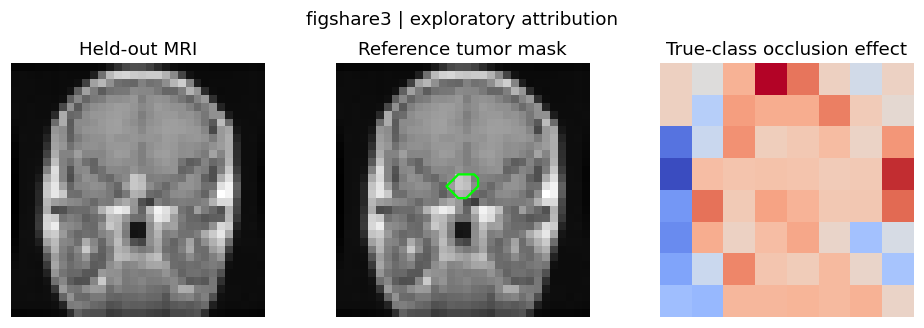

,cohort,image_id,analysis_unit,model,label,tumor_fraction,tumor_probability_drop,control_probability_drop,mask_localization_auc,random_weight_map_spearman
0,figshare3,56548a38bfaebf0340b1f5da,unit_000049,Coherent5,pituitary,0.009,-0.001,-0.015,0.616,-0.157
1,figshare3,56548a38bfaebf0340b1f5da,unit_000049,Passive5,pituitary,0.009,0.007,0.021,0.426,NaN
2,figshare3,56548a38bfaebf0340b1f5da,unit_000049,QuadraticLift_LR,pituitary,0.009,-0.014,0.030,0.368,NaN
3,figshare3,3620cee2eb915e89b81523d2,unit_000049,Coherent5,pituitary,0.011,-0.003,-0.029,0.676,-0.208
4,figshare3,3620cee2eb915e89b81523d2,unit_000049,Passive5,pituitary,0.011,0.000,0.013,0.400,NaN
5,figshare3,3620cee2eb915e89b81523d2,unit_000049,QuadraticLift_LR,pituitary,0.011,-0.013,0.046,0.420,NaN
6,figshare3,82a413ff188d5a2ef66cc13e,unit_000049,Coherent5,pituitary,0.013,-0.005,-0.045,0.667,-0.350
7,figshare3,82a413ff188d5a2ef66cc13e,unit_000049,Passive5,pituitary,0.013,-0.003,0.009,0.398,NaN
8,figshare3,82a413ff188d5a2ef66cc13e,unit_000049,QuadraticLift_LR,pituitary,0.013,-0.014,0.065,0.431,NaN
9,figshare3,fbc7179a9d0e6f962084df27,unit_000146,Coherent5,meningioma,0.004,0.002,-0.000,0.500,-0.217


In [33]:
def predict_small_image(record,rep,ds,images):
    shifted=representation_from_images(rep,np.asarray(images))
    name=record["name"]
    logits=quantum_logits(shifted["direction"],shifted["angle"],record["weights"],name,ds["k"]) if name in QUANTUM_MODELS else predict_classical(record,classical_features(shifted,name))
    return softmax(logits/record["temperature"],axis=1)
def occlusion_map(record,rep,ds,x,label,block=4):
    variations=[]
    for top in range(0,32,block):
        for left in range(0,32,block):
            changed=x.copy(); changed[top:top+block,left:left+block]=np.median(x)
            variations.append(changed.ravel())
    base=predict_small_image(record,rep,ds,[x.ravel()])[0,label]
    probabilities=predict_small_image(record,rep,ds,variations)[:,label]
    grid=(base-probabilities).reshape(32//block,32//block)
    return np.repeat(np.repeat(grid,block,axis=0),block,axis=1)
LOCALIZATION_ROWS=[]
for ds in DATASETS.values():
    frame=ds["manifest"]; available=frame.query("partition == 'test' and reader == 'cheng'")
    if available.empty: continue
    exp=EXPERIMENTS[f"{ds['name']}/robust"]; rep=exp["rep"]; run=exp["runs"][CFG["seeds"][0]]
    limit=2 if PROFILE=="smoke" else (3 if PROFILE=="pilot" else 9)
    chosen=available.groupby("label_id",group_keys=False).head(max(1,limit//ds["k"]))
    plotted=False
    for i,row in chosen.iterrows():
        native,mask,_,_=read_cheng_mat(row.path)
        if mask is None: continue
        x=resize_float(normalize_image(native),32)
        m=np.asarray(Image.fromarray(mask.astype("uint8")).resize((32,32),Image.Resampling.NEAREST)).astype(bool)
        if m.sum()==0 or m.all(): continue
        displaced=np.roll(m,shift=(12,12),axis=(0,1))
        for name in ["Coherent5","Passive5","QuadraticLift_LR"]:
            record=run["models"][name]; label=int(row.label_id)
            tumor,control=x.copy(),x.copy()
            tumor[m]=np.median(x); control[displaced]=np.median(x)
            p=predict_small_image(record,rep,ds,[x.ravel(),tumor.ravel(),control.ravel()])[:,label]
            heat=occlusion_map(record,rep,ds,x,label)
            localization_auc=roc_auc_score(m.ravel(),heat.ravel())
            random_corr=np.nan
            if name=="Coherent5":
                randomized=dict(record,weights=np.random.default_rng(113).uniform(-np.pi,np.pi,(N_LAYERS,4,3)))
                random_heat=occlusion_map(randomized,rep,ds,x,label)
                random_corr=float(scipy.stats.spearmanr(heat.ravel(),random_heat.ravel()).statistic)
            LOCALIZATION_ROWS.append(dict(cohort=ds["name"],image_id=row.image_id,analysis_unit=row.analysis_unit,
                model=name,label=row.label,tumor_fraction=float(m.mean()),
                tumor_probability_drop=float(p[0]-p[1]),control_probability_drop=float(p[0]-p[2]),
                mask_localization_auc=float(localization_auc),random_weight_map_spearman=random_corr))
            if name=="Coherent5" and not plotted:
                fig,axes=plt.subplots(1,3,figsize=(9,3))
                axes[0].imshow(x,cmap="gray"); axes[0].set_title("Held-out MRI")
                axes[1].imshow(x,cmap="gray"); axes[1].contour(m,levels=[0.5],colors=["lime"]); axes[1].set_title("Reference tumor mask")
                axes[2].imshow(heat,cmap="coolwarm"); axes[2].set_title("True-class occlusion effect")
                for axis in axes: axis.axis("off")
                fig.suptitle(ds["name"]+" | exploratory attribution")
                fig.tight_layout(); fig.savefig(ds["folder"]/"figure_attribution.png",bbox_inches="tight")
                plt.show(); plt.close(fig); plotted=True
LOCALIZATION_TABLE=pd.DataFrame(LOCALIZATION_ROWS)
LOCALIZATION_TABLE.to_csv(RUN_ROOT/"localization_sanity.csv",index=False)
if len(LOCALIZATION_TABLE): display(LOCALIZATION_TABLE.round(3))
else: print("Native tumor masks unavailable in these execution cohorts.")

### Cell 34 — Export figures suitable for a manuscript draft

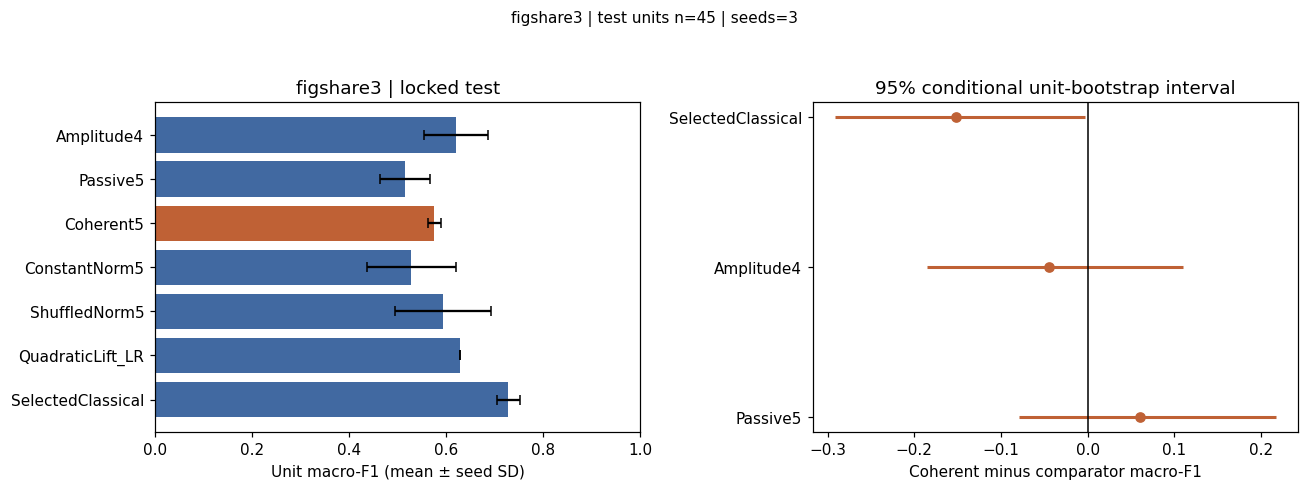

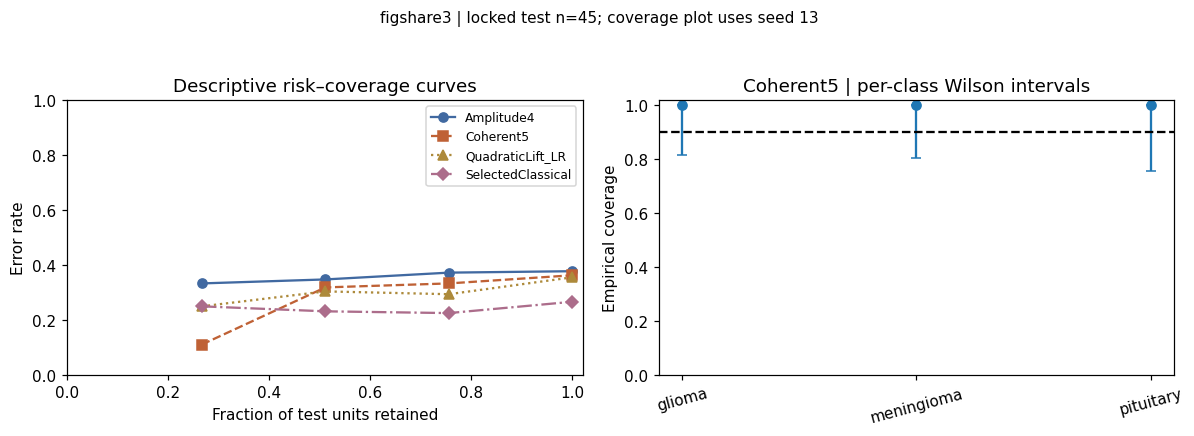

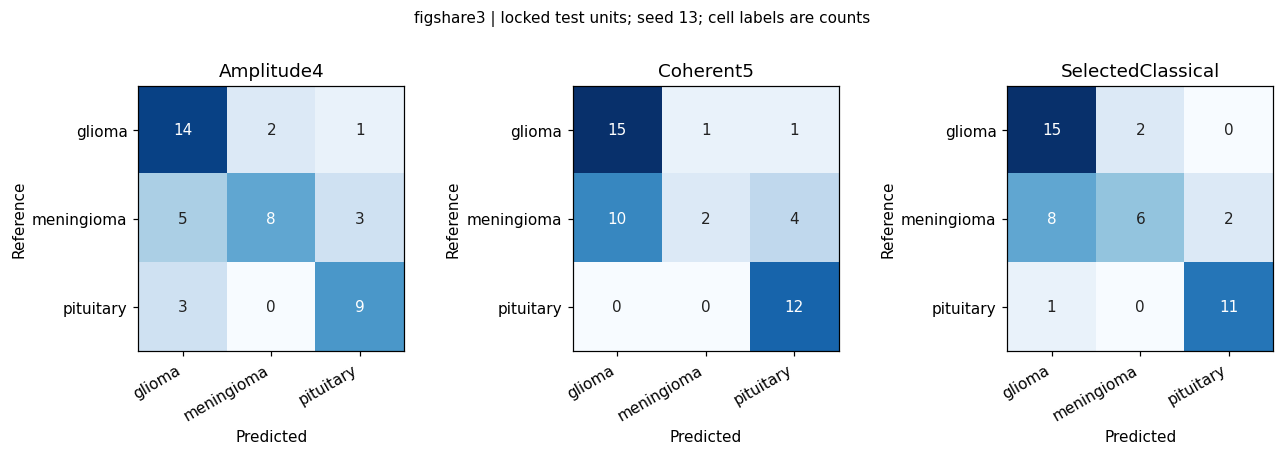

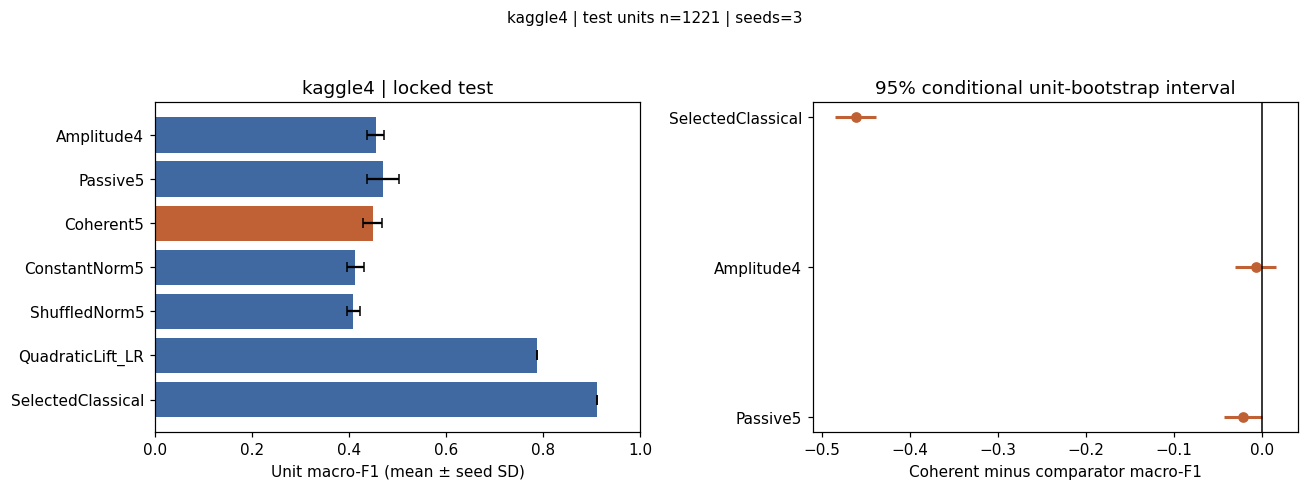

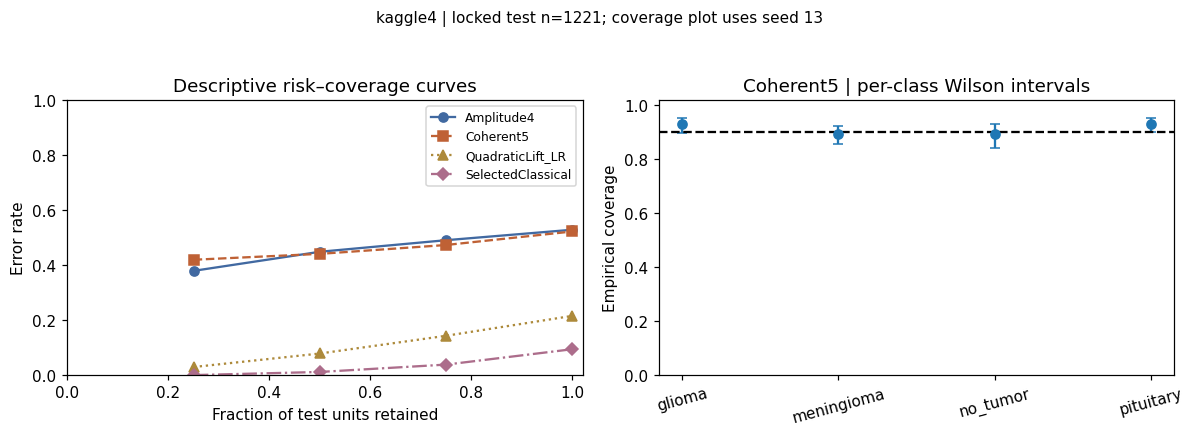

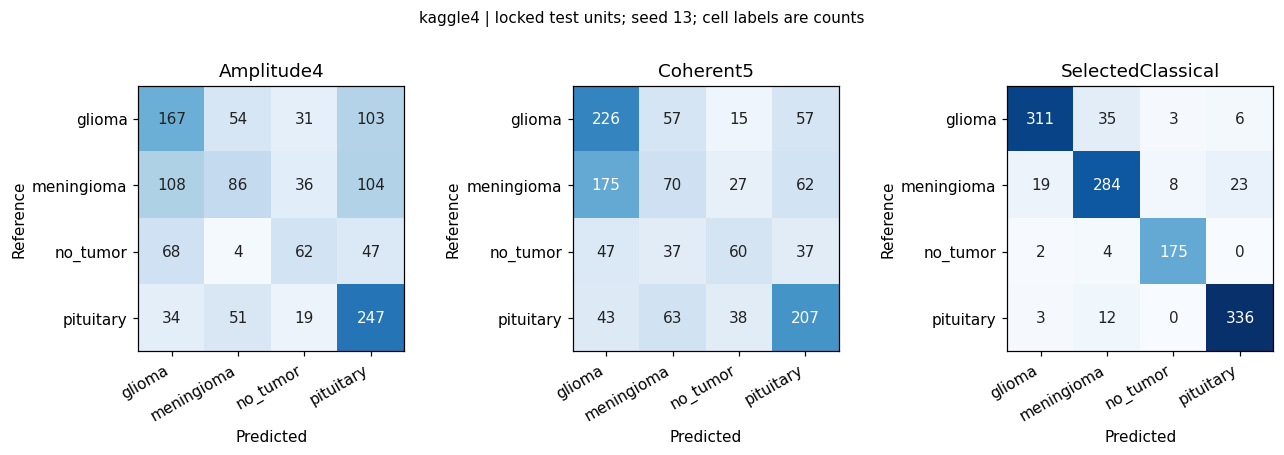

In [34]:
for ds in DATASETS.values():
    key=ds["name"]+"/robust"; exp=EXPERIMENTS[key]
    names=["Amplitude4","Passive5","Coherent5","ConstantNorm5","ShuffledNorm5","QuadraticLift_LR","SelectedClassical"]
    table=METRIC_TABLE.loc[
        METRIC_TABLE.cohort.eq(ds["name"]) & METRIC_TABLE["mode"].eq("robust")]
    avg=table.groupby("model").macro_f1.agg(["mean","std"]).reindex(names)
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    fig.suptitle(f"{ds['name']} | test units n={int(avg.shape[0] and table.units.iloc[0])} | seeds={len(exp['runs'])}",fontsize=10)
    pos=np.arange(len(names))
    mark_colors=["#bf6135" if name=="Coherent5" else "#4169a1" for name in names]
    axes[0].barh(pos,avg["mean"],xerr=avg["std"].fillna(0),color=mark_colors,capsize=3)
    axes[0].set_yticks(pos,names); axes[0].invert_yaxis(); axes[0].set_xlim(0,1)
    axes[0].set_xlabel("Unit macro-F1 (mean ± seed SD)")
    axes[0].set_title(ds["name"]+" | locked test")
    c=CONTRASTS.loc[CONTRASTS.cohort.eq(ds["name"])&CONTRASTS["mode"].eq("robust")]
    axes[1].hlines(np.arange(len(c)),c.ci_low,c.ci_high,color="#bf6135",linewidth=2)
    axes[1].scatter(c.delta_macro_f1,np.arange(len(c)),color="#bf6135")
    axes[1].axvline(0,color="black",lw=1); axes[1].set_yticks(np.arange(len(c)),c.model_b)
    axes[1].set_xlabel("Coherent minus comparator macro-F1")
    axes[1].set_title("95% conditional unit-bootstrap interval")
    fig.tight_layout(rect=(0,0,1,0.94)); fig.savefig(ds["folder"]/"figure_primary.png",bbox_inches="tight")
    fig.savefig(ds["folder"]/"figure_primary.pdf",bbox_inches="tight")
    plt.show(); plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    fig.suptitle(f"{ds['name']} | locked test n={int(table.units.iloc[0])}; coverage plot uses seed {CFG['seeds'][0]}",fontsize=10)
    risk=RISK_COVERAGE.loc[RISK_COVERAGE.cohort.eq(ds["name"])&RISK_COVERAGE["mode"].eq("robust")]
    palette={"Amplitude4":"#4169a1","Coherent5":"#bf6135","QuadraticLift_LR":"#ad8a3b","SelectedClassical":"#ac6d8b"}
    styles={"Amplitude4":("o","-"),"Coherent5":("s","--"),"QuadraticLift_LR":("^",":"),"SelectedClassical":("D","-.")}
    for name in palette:
        values=risk.loc[risk.model.eq(name)].groupby("retained_fraction").selective_risk.mean()
        marker,style=styles[name]
        axes[0].plot(values.index,values.values,marker=marker,linestyle=style,color=palette[name],label=name)
    axes[0].set(xlim=(0,1.02),ylim=(0,1),xlabel="Fraction of test units retained",ylabel="Error rate",
        title="Descriptive risk–coverage curves"); axes[0].legend(fontsize=8)
    coverage=CLASS_RELIABILITY.loc[CLASS_RELIABILITY.cohort.eq(ds["name"])&
        CLASS_RELIABILITY["mode"].eq("robust")&CLASS_RELIABILITY.model.eq("Coherent5")]
    seed=CFG["seeds"][0]; coverage=coverage.loc[coverage.seed.eq(seed)]
    x=np.arange(len(coverage))
    axes[1].errorbar(x,coverage.coverage,yerr=[coverage.coverage-coverage.ci_low,coverage.ci_high-coverage.coverage],
        fmt="o",capsize=3)
    axes[1].set_xticks(x,coverage.label,rotation=15); axes[1].axhline(1-ALPHA,color="black",ls="--")
    axes[1].set(ylim=(0,1.02),ylabel="Empirical coverage",title="Coherent5 | per-class Wilson intervals")
    fig.tight_layout(rect=(0,0,1,0.94)); fig.savefig(ds["folder"]/"figure_reliability.png",bbox_inches="tight")
    plt.show(); plt.close(fig)
    # Same first-seed, single-model estimand; no unexplained OOF/seed ensembling.
    confusion_models=["Amplitude4","Coherent5","SelectedClassical"]
    first_run=exp["runs"][CFG["seeds"][0]]
    matrices=[]
    for name in confusion_models:
        prediction=first_run["test_predictions"][name]
        matrices.append(confusion_matrix(prediction.label_id,prediction.prediction,labels=np.arange(ds["k"])))
    fig,axes=plt.subplots(1,3,figsize=(12,4))
    vmax=max(m.max() for m in matrices)
    for axis,name,matrix in zip(axes,confusion_models,matrices):
        axis.imshow(matrix,cmap="Blues",vmin=0,vmax=max(vmax,1))
        for row in range(ds["k"]):
            for col in range(ds["k"]):
                axis.text(col,row,str(matrix[row,col]),ha="center",va="center",
                    color="white" if matrix[row,col]>vmax/2 else "#222222")
        axis.set_title(name); axis.set_xlabel("Predicted"); axis.set_ylabel("Reference")
        axis.set_xticks(np.arange(ds["k"]),ds["labels"],rotation=30,ha="right")
        axis.set_yticks(np.arange(ds["k"]),ds["labels"])
    fig.suptitle(f"{ds['name']} | locked test units; seed {CFG['seeds'][0]}; cell labels are counts",fontsize=10)
    fig.tight_layout(rect=(0,0,1,0.93))
    fig.savefig(ds["folder"]/"figure_confusion.png",bbox_inches="tight")
    fig.savefig(ds["folder"]/"figure_confusion.pdf",bbox_inches="tight")
    plt.show(); plt.close(fig)

## Validation and paper preparation
### Cell 35 — Reconcile every result and distinguish submission requirements from superiority
Validity checks cannot certify acceptance. A rigorous null result can support a benchmarking
paper. A positive p value cannot repair missing patient IDs, external provenance, inadequate
sample size or an unverified novelty claim. Each claim must fit the task's dataset and taxonomy.

In [35]:
VALIDATION_ROWS=[]
for key,experiment in EXPERIMENTS.items():
    ds,rep=experiment["ds"],experiment["rep"]; frame,k=ds["manifest"],ds["k"]
    errors=[]
    for seed,run in experiment["runs"].items():
        for name,table in run["test_predictions"].items():
            value=metrics(table.label_id,unit_probs(table,k))["macro_f1"]
            saved=METRIC_TABLE.loc[METRIC_TABLE.cohort.eq(ds["name"])&METRIC_TABLE["mode"].eq(rep["mode"])&
                METRIC_TABLE.seed.eq(seed)&METRIC_TABLE.model.eq(name),"macro_f1"].iloc[0]
            errors.append(abs(value-saved))
    disjoint=frame.groupby("analysis_unit").partition.nunique().max()==1
    known=frame.loc[frame.patient_id.ne("")]
    patient_disjoint=known.empty or known.groupby("patient_id").partition.nunique().max()==1
    complete=len(experiment["runs"])==(len(CFG["seeds"]) if rep["mode"]=="robust" else 1)
    for seed,run in experiment["runs"].items():
        complete &= set(QUANTUM_MODELS+CLASSICAL_MODELS).issubset(run["models"])
        complete &= all("temperature" in r and "conformal" in r for r in run["models"].values())
    status=EXTERNAL_STATUS.loc[EXTERNAL_STATUS.cohort.eq(ds["name"])]
    external=bool(len(status) and status.status.eq("executed").all())
    observed=CONTRASTS.loc[CONTRASTS.cohort.eq(ds["name"])&CONTRASTS["mode"].eq(rep["mode"])&
        CONTRASTS.model_b.eq("SelectedClassical")].iloc[0]
    passed=all([max(errors)<1e-10,disjoint,patient_disjoint,complete])
    VALIDATION_ROWS.append(dict(cohort=ds["name"],mode=rep["mode"],
        metric_reconciliation=max(errors)<1e-10,partition_disjoint=bool(disjoint),
        known_patient_disjoint=bool(patient_disjoint),planned_models_complete=bool(complete),
        internal_validity=bool(passed),paper_profile=PROFILE=="paper",
        true_patient_units=ds["audit"]["complete_patient_unit_claim"],
        practical_cnn_executed=ds["cnn"] is not None,external_executed=external,
        superiority_supported=bool(PROFILE=="paper" and rep["mode"]=="robust" and
            ds["audit"]["complete_patient_unit_claim"] and observed.delta_macro_f1>0 and
            observed.holm_p<0.05 and observed.ci_low>0),
        clinical_generalization_supported=False,
        quantum_computational_advantage_supported=False,
        human_novelty_review_complete=False,human_ethics_and_licensing_review_complete=False,
        submission_status="evidence generated; human study/novelty/reporting review required"))
    assert passed,"Internal validation failed for "+key
VALIDATION_TABLE=pd.DataFrame(VALIDATION_ROWS)
VALIDATION_TABLE.to_csv(RUN_ROOT/"claim_and_validity_assessment.csv",index=False)
display(VALIDATION_TABLE)
print("A completed real-data run is an experiment package, not an automatically publishable paper.")

,cohort,mode,metric_reconciliation,partition_disjoint,known_patient_disjoint,planned_models_complete,internal_validity,paper_profile,true_patient_units,practical_cnn_executed,external_executed,superiority_supported,clinical_generalization_supported,quantum_computational_advantage_supported,human_novelty_review_complete,human_ethics_and_licensing_review_complete,submission_status
0,figshare3,robust,True,True,True,True,True,True,True,True,False,False,False,False,False,False,evidence generated; human study/novelty/report...
1,figshare3,raw,True,True,True,True,True,True,True,True,False,False,False,False,False,False,evidence generated; human study/novelty/report...
2,kaggle4,robust,True,True,True,True,True,True,False,True,False,False,False,False,False,False,evidence generated; human study/novelty/report...
3,kaggle4,raw,True,True,True,True,True,True,False,True,False,False,False,False,False,False,evidence generated; human study/novelty/report...


A completed real-data run is an experiment package, not an automatically publishable paper.


### Cell 36 — Create an evidence-backed manuscript working draft

In [36]:
draft=[]
draft.append("# Norm Information and Reliability in Small Quantum Brain MRI Classifiers\n")
draft.append("WORKING DRAFT — authors must verify novelty, dataset licensing, ethical status and all claims before submission.\n")
if PROFILE!="paper":
    draft.append("ENGINEERING RUN ONLY. The following numbers must not be used as scientific results.\n")
draft.append("## Abstract (generated observations; revise for the target journal)\n")
draft.append("We evaluate amplitude, passive-ancilla and coherent-ancilla quantum-state classifiers against norm-matched classical controls, with disjoint model selection, temperature and conformal calibration, and locked grouped testing. No computational quantum advantage is claimed.\n")
for ds in DATASETS.values():
    key=ds["name"]+"/robust"
    row=SUMMARY.loc[SUMMARY.cohort.eq(ds["name"])&SUMMARY["mode"].eq("robust")&SUMMARY.model.eq("Coherent5")].iloc[0]
    contrasts=CONTRASTS.loc[CONTRASTS.cohort.eq(ds["name"])&CONTRASTS["mode"].eq("robust")]
    draft.append(f"### {ds['name']} ({ds['k']} classes; report separately)\n")
    draft.append(f"Retained images: {len(ds['manifest'])}; analysis units: {ds['manifest'].analysis_unit.nunique()}; patient-ID coverage: {ds['audit']['patient_coverage']:.1%}. Coherent test unit macro-F1 averaged over training seeds was {row.macro_f1_mean:.4f}, with seed SD {(format(row.macro_f1_seed_sd, '.4f') if np.isfinite(row.macro_f1_seed_sd) else 'not estimated (one seed)')}. Test units: {int(row.units)}.\n")
    draft.append(contrasts[["model_a","model_b","delta_macro_f1","ci_low","ci_high","holm_p"]].to_markdown(index=False,floatfmt=".4f")+"\n")
    draft.append("Intervals condition on the fitted models and fixed split; they exclude institution and refitting variability. Comparator families were selected only on the selection partition.\n")
draft.append("## Methods\n")
draft.append(f"Protocol: {PROTOCOL_HASH}. Fixed five-way grouped partition fractions: {SPLIT_FRACTIONS}; PCA dimensions: 16; rotations: 24; fit-slice cap per unit: {CFG['fit_slices_per_unit']}; optimizer: Adam; selection grid: {CFG['lr_grid']}; maximum epochs: {CFG['epochs']}. Native simulator checked against PennyLane and finite differences. Image transforms and PCA/norm limits are fit or specified without test outcomes. Class-balanced training weights give equal total weight to each fit unit.\n")
draft.append("Probability temperature is fitted using distinct units. Mondrian conformal thresholds use another independent partition. Clinical subjects are not inferred from filenames. Conflicting exact images and ambiguous single-diagnosis units are excluded with a ledger; no labels are automatically reassigned.\n")
draft.append("## Results tables and figures\n")
draft.append("- model_summary.csv: held-out predictive metrics and seed SD.\n- paired_contrasts.csv: conditional unit-bootstrap intervals and Holm-corrected permutation tests.\n- conformal_metrics.csv and class_conformal_coverage.csv: reliability and calibration class counts.\n- acquisition_stress.csv: synthetic acquisition perturbations.\n- circuit_resources.csv and shot_noise_diagnostics.csv: explicit input-loading and noise diagnostics.\n- external_status.csv: independent external validation availability.\n- localization_sanity.csv: exploratory tumor-mask and attribution checks.\n")
draft.append("## Interpretation\n")
draft.append("If coherent fusion does not outperform passive fusion and matched classical models, report that result directly. Exact trained-circuit equivalence is expected from the quadratic-state identity; it excludes an inference computational-advantage claim for these small circuits. Norm-related gains may reflect acquisition or preprocessing features. Synthetic corruption robustness is not clinical scanner generalization. High specificity alone is insufficient for diagnostic utility.\n")
draft.append("## Limitations\n")
draft.append("Native Figshare contains three tumor classes, not normal controls. Kaggle is a composite four-class benchmark with incomplete patient provenance. They may share source images and are not independent external cohorts. A small number of calibration patients can yield uninformative conformal sets. Fixed-split inference and a limited number of seeds do not capture full model-development variability. A frozen ImageNet CNN probe is a practical baseline, not a fully tuned clinical CNN. Hardware results, prospective validation, subgroup fairness and clinical utility are not established by this notebook.\n")
draft.append("## Required human-written sections\n")
draft.append("Authors/affiliations; verified related-work novelty; introduction and clinical motivation; dataset inclusion/diagnostic reference standard; ethics/consent or justified public-data exemption; licensing; detailed discussion; subgroup limitations; conflicts/funding; author contributions; data/code availability; completed TRIPOD+AI and journal checklist; final bibliography.\n")
draft.append("## Submission decision\n")
draft.append("All internal validity checks must pass. Positive superiority is not mandatory for a rigorous benchmarking or null-result article. Acceptance depends on contribution, evidence quality, writing and editorial/peer review; no automatic gate certifies publishability.\n")
(RUN_ROOT/"manuscript_working_draft.md").write_text("\n".join(draft))
display(Markdown("\n".join(draft[:8])))

# Norm Information and Reliability in Small Quantum Brain MRI Classifiers

WORKING DRAFT — authors must verify novelty, dataset licensing, ethical status and all claims before submission.

## Abstract (generated observations; revise for the target journal)

We evaluate amplitude, passive-ancilla and coherent-ancilla quantum-state classifiers against norm-matched classical controls, with disjoint model selection, temperature and conformal calibration, and locked grouped testing. No computational quantum advantage is claimed.

### figshare3 (3 classes; report separately)

Retained images: 3064; analysis units: 233; patient-ID coverage: 100.0%. Coherent test unit macro-F1 averaged over training seeds was 0.5759, with seed SD 0.0142. Test units: 45.

| model_a   | model_b           |   delta_macro_f1 |   ci_low |   ci_high |   holm_p |
|:----------|:------------------|-----------------:|---------:|----------:|---------:|
| Coherent5 | Passive5          |           0.0600 |  -0.0797 |    0.2172 |   1.0000 |
| Coherent5 | Amplitude4        |          -0.0446 |  -0.1859 |    0.1104 |   1.0000 |
| Coherent5 | SelectedClassical |          -0.1523 |  -0.2916 |   -0.0033 |   0.2139 |

Intervals condition on the fitted models and fixed split; they exclude institution and refitting variability. Comparator families were selected only on the selection partition.


### Cell 37 — Save limitations, reporting checklist, model cards and references
Related work was reviewed on 1 October 2026. Encoding, norm preservation, hybrid MRI models,
classical QML surrogates and conformal prediction all have prior art. A search does not prove
that this particular empirical combination is new. Verify the final contribution immediately
before submission.

In [37]:
REFERENCES=[
 dict(id="KP2026",title="A quantum computing approach for brain tumor image classification using amplitude encoding technique",url="https://doi.org/10.1007/s44464-026-00005-z",role="Starting study; standard simulator and PCA-amplitude design"),
 dict(id="Bowles2024",title="Better than classical? The subtle art of benchmarking quantum machine learning models",url="https://arxiv.org/abs/2403.07059",role="Fair controls and benchmarking"),
 dict(id="Haddou2025",title="HQCM-EBTC: A Hybrid Quantum-Classical Model for Explainable Brain Tumor Classification",url="https://arxiv.org/abs/2506.21937",role="Existing hybrid/interpretability work; a preprint"),
 dict(id="Soliman2026",title="A hybrid quantum-classical framework for MRI-based deep brain tumor segmentation and classification",url="https://doi.org/10.1038/s41598-026-58823-1",role="Recent QFormer-Brain hybrid segmentation/classification work; adding a hybrid encoder alone is not a verified novel contribution"),
 dict(id="ChengData",title="brain tumor dataset, version 8",url="https://doi.org/10.6084/m9.figshare.1512427.v8",role="Original patient/mask-bearing source; three tumor classes; CC BY 4.0 publisher record"),
 dict(id="KaggleData",title="Brain Tumor MRI Dataset",url="https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset",role="Four-class benchmark; source overlap warning"),
 dict(id="Angelopoulos2021",title="A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification",url="https://arxiv.org/abs/2107.07511",role="Finite-sample calibration and exchangeability assumptions"),
 dict(id="TRIPODAI2024",title="TRIPOD+AI statement",url="https://doi.org/10.1136/bmj-2023-078378",role="Clinical prediction reporting"),
 dict(id="TRIPODCluster2023",title="Transparent reporting of multivariable prediction models developed or validated using clustered data: TRIPOD-Cluster checklist",url="https://doi.org/10.1136/bmj-2022-071018",role="Clustered data reporting"),
 dict(id="Normalization2020",title="Implementation of a Hamming distance-like genomic quantum classifier using inner products on ibmqx2 and ibmq_16_melbourne",url="https://doi.org/10.1007/s42484-020-00017-7",role="Prior discussion of normalization ambiguity; norm preservation alone is not new"),
 dict(id="PennyLaneDocs",title="AmplitudeEmbedding and matrix documentation",url="https://docs.pennylane.ai/en/stable/code/api/pennylane.AmplitudeEmbedding.html",role="State preparation semantics; code uses pinned PennyLane 0.42.3"),
 dict(id="TorchvisionDocs",title="ResNet18 model documentation",url="https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html",role="Frozen feature comparator and model weight provenance"),
]
write_json(RUN_ROOT/"references.json",REFERENCES)
(RUN_ROOT/"references.md").write_text("# References\n\n"+"\n\n".join(
    f"- **{r['id']}**. {r['title']}. {r['url']}\n  Role: {r['role']}" for r in REFERENCES))
checklist=[
 ("Target task and clinical setting","Authors must specify the diagnostic question and reference standard."),
 ("Dataset lineage and license","Use provenance.json; inspect dataset licences and downstream rights."),
 ("Unit and inclusion/exclusion flow","Use manifests, exclusions.csv and locked_split_registry.csv."),
 ("Missing IDs and scanner metadata","Do not claim patient or site generalization when these are missing."),
 ("Sample size and precision","Report test/calibration units, class counts and confidence intervals; add an independent cohort for narrow effects."),
 ("Preprocessing and selection","Use protocol.json and search ledgers; no tuning after test inspection."),
 ("Complete classical comparison","Report norm-matched quadratic model, SVM, low-rank and higher-resolution CNN probe; consider tuned clinical CNNs."),
 ("Uncertainty and multiplicity","Report conditional interval scope, Holm family and seed variability."),
 ("Reliability under shift","Report conformal class counts, set size, coverage intervals and failure under corruption."),
 ("Explanation validity","Use actual masks and random-weight sanity checks; avoid clinical localization claims."),
 ("Quantum resources","Report input loading, fixed/fitted classical parameters, search time and generic-noise limitations."),
 ("External independence","Use overlap exclusions and attested institution/provenance; manual verification required."),
 ("Ethics and conflicts","Write approval/exemption, consent basis, funding and conflicts accurately."),
 ("Novelty","Repeat related-work review; coherent ancilla use or norm encoding alone is not a proven first."),
 ("Reproducibility","Share environment, hashes, split registry and allowable prediction/code artifacts."),
 ("Test reuse","Document every look at the locked test; a new code hash does not repair test reuse."),
]
pd.DataFrame(checklist,columns=["item","required_action"]).to_csv(RUN_ROOT/"reporting_checklist.csv",index=False)
model_cards=[]
for ds in DATASETS.values():
    model_cards.append(dict(cohort=ds["name"],labels=ds["labels"],purpose="research benchmark",
        prohibited_claims=["clinical deployment readiness","guaranteed publication","computational quantum advantage"],
        patient_id_coverage=ds["audit"]["patient_coverage"],fit_slice_cap=CFG["fit_slices_per_unit"],
        prediction_unit="mean slice probabilities per analysis unit",external_status=EXTERNAL_STATUS.loc[EXTERNAL_STATUS.cohort.eq(ds["name"])].to_dict("records"),
        limitations=["finite subjects","possible acquisition shortcuts","small-register classical simulation","unverified clinical impact"]))
write_json(RUN_ROOT/"model_cards.json",model_cards)
print("Draft, reference list, reporting checklist and model cards saved.")

Draft, reference list, reporting checklist and model cards saved.


### Cell 38 — Package the complete evidence bundle
The ZIP includes results, model checkpoints, source provenance and environment, but no raw MRI
files. Subject IDs and prediction tables still need a privacy/licensing review before sharing.
Your original uploaded notebook remains unchanged.

In [38]:
readme=f'''# QML norm/coherence study bundle
Profile: {PROFILE}
Protocol hash: {PROTOCOL_HASH}
Version: {VERSION}
This is a reproducible experiment package, not an acceptance certificate.
Open manuscript_working_draft.md only after inspecting claim_and_validity_assessment.csv.
Figures/tables reflect this executed profile. Synthetic and pilot results are not paper evidence.
Checkpoints bind the protocol, seed, hyperparameters, preprocessing and input-content fingerprint.
The parent environment JSON and pip freeze describe software; raw input data are not included.
For a fresh Colab session run this notebook again with the same profile, cache and Drive result folder.
An unchanged protocol/data hash resumes completed candidates. Archive the original study before revisions.
Independent external data, final novelty verification and ethics/reporting statements require human input.
'''
(RUN_ROOT/"README.md").write_text(readme)
archive=ROOT/(RUN_ROOT.name+"_evidence.zip")
with zipfile.ZipFile(archive,"w",compression=zipfile.ZIP_DEFLATED) as zipped:
    for path in sorted(RUN_ROOT.rglob("*")):
        if path.is_file(): zipped.write(path,path.relative_to(RUN_ROOT))
    zipped.write(ROOT/"environment.json","environment.json")
    zipped.write(ROOT/"environment_freeze.txt","environment_freeze.txt")
print("Evidence ZIP:",archive)
print("Results:",RUN_ROOT)
if DOWNLOAD_ZIP and IN_COLAB:
    from google.colab import files
    files.download(str(archive))
display(Markdown("**Completed.** Review the validity table, real-data results and checklist before writing submission claims."))

Evidence ZIP: /content/qml_norm_coherence_v2/paper_bd11a4851076_evidence.zip
Results: /content/qml_norm_coherence_v2/paper_bd11a4851076


**Completed.** Review the validity table, real-data results and checklist before writing submission claims.

## Takeaways
1. A rigorous run creates evidence, not a guaranteed publication.
2. Coherent norm fusion is a testable candidate contribution; its novelty must be verified.
3. The passive ancilla is an exact norm-controlled mixture. All these small circuits have
   exact quadratic classical inference equivalents.
4. Figshare and Kaggle answer different three- and four-class questions, and can share source
   images. Neither should be relabeled as an independent external cohort.
5. Missing patient/scanner provenance, narrow confidence intervals from repeated slices, or
   non-independent external validation cannot be fixed by higher apparent accuracy.
6. Negative or equivalent performance can support a carefully scoped benchmarking paper.
   Clinical utility, hardware advantage and reviewer acceptance require additional evidence.